# CoDetect – Financial Fraud Detection With Anomaly Feature Detection
### Stage 1: data, features, two Isolation Forests, evaluation and saved artifacts

**Research question.** Do relationship features from the transaction graph change how well an
unsupervised anomaly detector separates money-laundering transactions from normal ones,
compared with transaction features alone?

* **Model 1 – Transaction-only Isolation Forest.** Features of the transaction plus the sender's and receiver's recent activity.
* **Model 2 – Graph-enhanced Isolation Forest.** The same features plus graph-derived features (degrees, counterparties, activity, volume).

**Data.** IBM *Transactions for Anti-Money Laundering* (HI-Small). It is synthetic, comes from IBM's multi-agent
simulation, carries labels, and is licensed CDLA-Sharing-1.0.

**Ground rules followed throughout**
* The laundering label is used **only for evaluation** (and for highlighting in exploratory charts). It is never a model input.
* Every history feature of a transaction uses only transactions from the **previous 24 hours, strictly earlier minutes**.
* The split is chronological. Preprocessing, exchange rates, score normalisation and risk cut-points are fitted on training data only.
* Model settings are chosen on validation data. The test days are scored **once**, at the end.
* An anomaly score measures **how unusual** a transaction is. It is **not** a probability of fraud.

All feature, scoring and explanation logic is imported from `services/`, so Flask (Stage 2) runs exactly the same code.

## 1. Project setup
Set `CODETECT_RUN_MODE=full` in the environment, or `RUN_MODE` in `config.py`, to train on every training row.
Quick mode trains each forest on a fixed random sample of 300,000 training rows and draws graphs from a 3-hour window.
Features are always computed on every row in both modes.

In [1]:
import os, sys, platform, json, time, warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "config.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import sklearn, joblib, networkx as nx, matplotlib, seaborn as sns, plotly
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import plotly.graph_objects as go
from IPython.display import display, Markdown
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             roc_curve, precision_score, recall_score, f1_score, confusion_matrix)

import config as C
from services import feature_engineering as fe
from services import modeling as md
from services.fraud_inference import FraudInference, ARTIFACT_FILES, sha256

RUN_MODE = os.environ.get("CODETECT_RUN_MODE", C.RUN_MODE)
MODE = C.RUN_MODES[RUN_MODE]
SEED = C.RANDOM_SEED
rng = np.random.default_rng(SEED)
for d in (C.DATA_PROCESSED, C.MODELS_DIR, C.FIGURES_DIR, C.METRICS_DIR, C.GRAPHS_DIR, C.REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")
NOTEBOOK_START = time.perf_counter()

if not C.TRANSACTIONS_FILE.exists():
    raise FileNotFoundError(
        f"{C.TRANSACTIONS_FILE} not found. Download HI-Small_Trans.csv as described in README section 2.")

versions = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
            "scikit-learn": sklearn.__version__, "joblib": joblib.__version__,
            "networkx": nx.__version__, "matplotlib": matplotlib.__version__,
            "seaborn": sns.__version__, "plotly": plotly.__version__}
print(json.dumps(versions, indent=2))
print("dataset file :", C.TRANSACTIONS_FILE.relative_to(ROOT),
      f"({C.TRANSACTIONS_FILE.stat().st_size / 1e6:.1f} MB)")
print("run mode     :", RUN_MODE, MODE)
print("random seed  :", SEED)
print("feature ver. :", fe.FEATURE_VERSION, "| history window:", fe.HISTORY_WINDOW_MINUTES, "minutes")

{
  "python": "3.12.10",
  "pandas": "3.1.1",
  "numpy": "2.5.5",
  "scikit-learn": "1.9.1",
  "joblib": "1.6.0",
  "networkx": "3.7",
  "matplotlib": "3.11.2",
  "seaborn": "0.13.2",
  "plotly": "7.1.0"
}
dataset file : data\raw\HI-Small_Trans.csv (475.7 MB)
run mode     : quick {'train_sample_rows': 300000}
random seed  : 42
feature ver. : 2.0.0 | history window: 1440 minutes


In [2]:
# Chart style: recessive grid/axes, thin marks, fixed colour roles.
# Two-series charts use categorical slots 1-2 (blue, orange); risk levels use the reserved
# status colours and are always labelled with text, never colour alone.
PAL = {"s1": "#2a78d6", "s2": "#eb6834", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
       "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb"}
RISK_COLORS = {"Low": "#0ca30c", "Medium": "#fab219", "High": "#ec835a", "Critical": "#d03b3b"}
LABEL_COLORS = {"Normal": PAL["s1"], "Laundering": PAL["s2"]}
MODEL_COLORS = {"transaction_only": PAL["s1"], "graph_enhanced": PAL["s2"]}
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_blue_red", ["#104281", "#3987e5", "#f0efec", "#e34948", "#9e2b2b"])

plt.rcParams.update({
    "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"], "savefig.facecolor": PAL["surface"],
    "axes.edgecolor": PAL["axis"], "axes.labelcolor": PAL["ink2"], "axes.titlecolor": PAL["ink"],
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "xtick.color": PAL["muted"], "ytick.color": PAL["muted"],
    "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.grid": True, "grid.color": PAL["grid"],
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 9,
    "font.family": ["Segoe UI", "DejaVu Sans"], "lines.linewidth": 2, "figure.dpi": 100})
FIGS = []

def save(fig, name):
    """Save to outputs/figures and show."""
    path = C.FIGURES_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    FIGS.append(path.name)
    plt.show()

def thousands(ax, axis="y"):
    fmt = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

def usd_log_ticks(ax, axis="x"):
    labels = {-6: "$0.000001", -3: "$0.001", 0: "$1", 3: "$1k", 6: "$1M", 9: "$1B", 12: "$1T"}
    a = ax.xaxis if axis == "x" else ax.yaxis
    a.set_major_locator(mticker.FixedLocator(list(labels)))
    a.set_major_formatter(mticker.FuncFormatter(lambda v, _: labels.get(int(round(v)), "")))

## 2. Dataset loading and inspection
The raw header repeats the column name `Account` (sender and receiver), so pandas renames the second one `Account.1`.
Bank codes have leading zeros, so bank and account columns are read as text.
The mapping from raw names to canonical names is configurable in `config.COLUMN_MAP`.

In [3]:
with open(C.TRANSACTIONS_FILE, encoding="utf-8") as fh:
    raw_header = fh.readline().strip().split(",")
print("raw header:", raw_header)

t0 = time.perf_counter()
raw = fe.load_transactions(C.TRANSACTIONS_FILE, C.COLUMN_MAP)
print(f"loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns in {time.perf_counter() - t0:.1f}s")
display(pd.Series(C.COLUMN_MAP, name="raw column").rename_axis("canonical name").to_frame())
display(raw.dtypes.rename("dtype").to_frame().T)
display(raw.head(6))

raw header: ['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']


loaded 5,078,345 rows x 11 columns in 2.7s


,raw column
canonical name,
timestamp,Timestamp
sender_bank,From Bank
sender_account,Account
receiver_bank,To Bank
receiver_account,Account.1
amount_received,Amount Received
receiving_currency,Receiving Currency
amount_paid,Amount Paid
payment_currency,Payment Currency


,timestamp,sender_bank,sender_account,receiver_bank,receiver_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,label
dtype,str,str,str,str,str,float64,str,float64,str,str,int64


,timestamp,sender_bank,sender_account,receiver_bank,receiver_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,label
0,2022/09/01 00:20,010,8000EBD30,010,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,03208,8000F4580,001,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,03209,8000F4670,03209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,012,8000F5030,012,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,010,8000F5200,010,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0
5,2022/09/01 00:03,001,8000F5AD0,001,8000F5AD0,6162.44,US Dollar,6162.44,US Dollar,Reinvestment,0


In [4]:
ts_probe = pd.to_datetime(raw["timestamp"], format=fe.TIMESTAMP_FORMAT, errors="coerce")
inspection = pd.Series({
    "rows": len(raw),
    "missing values (all columns)": int(raw.isna().sum().sum()),
    "exact duplicate rows": int(raw.duplicated().sum()),
    "unparseable timestamps": int(ts_probe.isna().sum()),
    "rows out of time order vs previous row": int((ts_probe.diff() < pd.Timedelta(0)).sum()),
    "max rows sharing one minute": int(ts_probe.value_counts().max()),
    "first timestamp": ts_probe.min(), "last timestamp": ts_probe.max(),
    "non-positive amounts": int(((raw["amount_paid"] <= 0) | (raw["amount_received"] <= 0)).sum()),
}, name="value").to_frame()
display(inspection)
display(raw.isna().sum().rename("missing").to_frame().T)
del ts_probe

,value
rows,5078345
missing values (all columns),0
exact duplicate rows,9
unparseable timestamps,0
rows out of time order vs previous row,2418736
max rows sharing one minute,11193
first timestamp,2022-09-01 00:00:00
last timestamp,2022-09-18 16:18:00
non-positive amounts,0


,timestamp,sender_bank,sender_account,receiver_bank,receiver_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,label
missing,0,0,0,0,0,0,0,0,0,0,0


## 3. Data cleaning and preprocessing decisions
| Issue found | Decision |
|---|---|
| Rows are not in time order | Sort by minute. History features rely on time, not on file order |
| Minute-resolution ties (up to ~11k rows in one minute) | Rows in the same minute cannot see each other (strictly-earlier rule) |
| An account id is unique only within its bank | Account key = `bank|account` |
| 9 exact duplicate rows, none labelled laundering | Dropped. They cannot be told apart from repeated payments, and there are only 9 |
| 15 currencies, including Bitcoin | Converted to USD at **rates implied by the data's own cross-currency rows**, fitted on warm-up and training days only |
| Invalid timestamps, amounts or ids | Dropped and counted. Nothing is repaired or invented |
| Categorical attributes (payment format, currency) | Kept as text here. One-hot encoded inside the model preprocessing, fitted on training data only |

**Chronological split.**
* **Warm-up, Sep 1:** builds 24h history only. It is never trained on or scored.
* **Train:** Sep 2–6.
* **Validation:** Sep 7–8.
* **Test:** Sep 9–10.
* **Excluded:** Sep 11–18. This is a simulation tail of 1,108 rows, about 58% laundering. It would inflate any metric, so it is shown only in the exploratory analysis.

In [5]:
t0 = time.perf_counter()
tx, clean_report = fe.clean_transactions(raw, reference_prefix="HI-Small")
del raw
tx["split"] = fe.assign_time_split(tx["timestamp"], C.SPLIT_WINDOWS)
print(f"cleaned in {time.perf_counter() - t0:.1f}s")
display(pd.Series(clean_report, name="count").to_frame().T)

fx = fe.fit_fx_rates(tx[tx["split"].isin(C.FX_FIT_SPLITS)])
assert not fx["currencies_without_rate"], fx["currencies_without_rate"]
tx["amount_usd"] = fe.to_usd(tx["amount_paid"], tx["payment_currency"], fx)
display(pd.DataFrame({"USD per unit": fx["rates"], "cross-currency observations": fx["n_observations"]})
        .sort_values("USD per unit").style.format({"USD per unit": "{:,.6f}", "cross-currency observations": "{:,.0f}"}))

SPLIT_ORDER = ["warmup", "train", "validation", "test", "excluded"]
split_tbl = (tx.groupby("split").agg(rows=("label", "size"), laundering=("label", "sum"),
                                     first=("timestamp", "min"), last=("timestamp", "max"))
               .reindex(SPLIT_ORDER))
split_tbl["laundering_rate_%"] = (100 * split_tbl["laundering"] / split_tbl["rows"]).round(4)
display(split_tbl)

cleaned in 30.6s


,input_rows,invalid_timestamp,invalid_amount,invalid_account_id,missing_category,dropped_invalid,dropped_exact_duplicates,output_rows
count,5078345,0,0,0,0,0,9,5078336


,USD per unit,cross-currency observations
Yen,0.009488,"1,822"
Ruble,0.012853,"1,253"
Rupee,0.013616,"1,856"
Mexican Peso,0.047297,708
Yuan,0.149307,"5,542"
Brazil Real,0.177101,500
Saudi Riyal,0.266588,541
Shekel,0.296121,"1,353"
Australian Dollar,0.707814,927
Canadian Dollar,0.757978,"1,264"


,rows,laundering,first,last,laundering_rate_%
split,,,,,
warmup,1114919,322,2022-09-01 00:00:00,2022-09-01 23:59:00,0.0289
train,2134000,2208,2022-09-02 00:00:00,2022-09-06 23:59:00,0.1035
validation,965521,1036,2022-09-07 00:00:00,2022-09-08 23:59:00,0.1073
test,862788,956,2022-09-09 00:00:00,2022-09-10 23:59:00,0.1108
excluded,1108,655,2022-09-11 00:05:00,2022-09-18 16:18:00,59.1155


In [6]:
# Export the cleaned dataset (labels kept in their own column for evaluation).
clean_cols = ["transaction_reference", "timestamp", "sender_bank", "sender_account", "receiver_bank",
              "receiver_account", "sender_id", "receiver_id", "amount_paid", "payment_currency",
              "amount_received", "receiving_currency", "payment_format", "amount_usd", "split", "label"]
clean_path = C.DATA_PROCESSED / "cleaned_transactions.csv.gz"
t0 = time.perf_counter()
tx[clean_cols].to_csv(clean_path, index=False, compression={"method": "gzip", "compresslevel": 1})
print(f"saved {clean_path.relative_to(ROOT)} ({clean_path.stat().st_size / 1e6:.0f} MB) "
      f"in {time.perf_counter() - t0:.0f}s")

saved data\processed\cleaned_transactions.csv.gz (247 MB) in 27s


## 4. Exploratory data analysis
These charts use all cleaned rows, including the excluded tail (it is marked where relevant).
Labels appear here only to describe the data.

In [7]:
y_all = tx["label"].astype(int)
accounts_all = pd.concat([tx["sender_id"], tx["receiver_id"]])
overview = pd.Series({
    "transactions": f"{len(tx):,}",
    "distinct accounts (bank|account)": f"{accounts_all.nunique():,}",
    "distinct banks": f"{pd.concat([tx['sender_bank'], tx['receiver_bank']]).nunique():,}",
    "labelled laundering": f"{int(y_all.sum()):,}",
    "laundering rate": f"{100 * y_all.mean():.4f}%",
    "self-transfers": f"{int((tx['sender_id'] == tx['receiver_id']).sum()):,}",
    "cross-currency transactions": f"{int((tx['payment_currency'] != tx['receiving_currency']).sum()):,}",
    "period": f"{tx['timestamp'].min()} -> {tx['timestamp'].max()}",
}, name="value").to_frame()
display(overview)

,value
transactions,"5,078,336"
distinct accounts (bank|account),"515,088"
distinct banks,"30,528"
labelled laundering,"5,177"
laundering rate,0.1019%
self-transfers,"591,212"
cross-currency transactions,"72,166"
period,2022-09-01 00:00:00 -> 2022-09-18 16:18:00


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


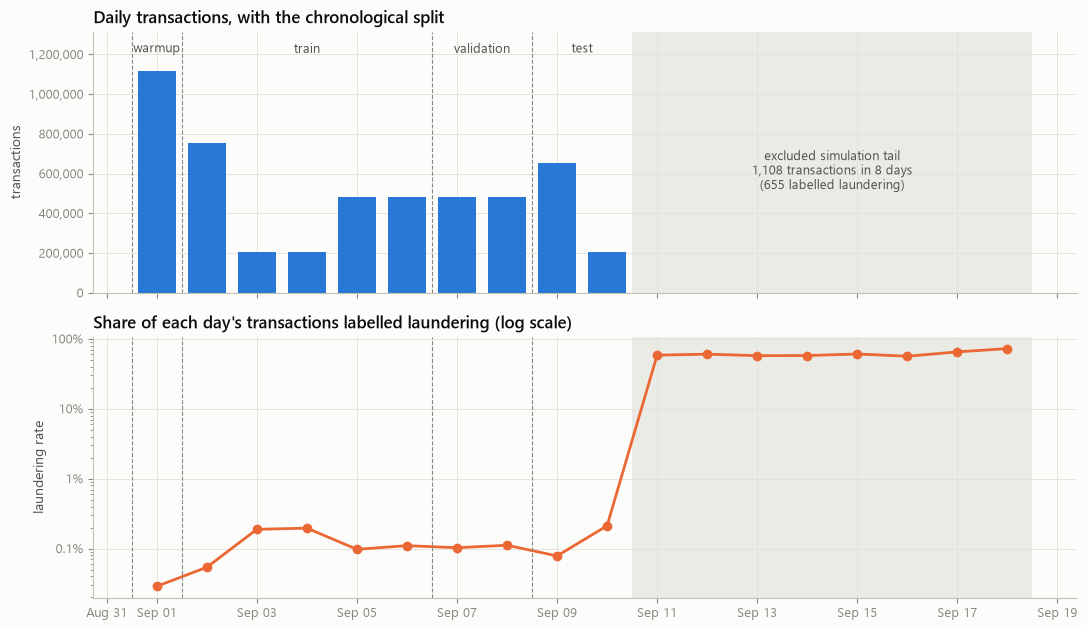

In [8]:
daily = tx.groupby(tx["timestamp"].dt.normalize()).agg(rows=("label", "size"), laundering=("label", "sum"))
daily["rate"] = 100 * daily["laundering"] / daily["rows"]
excluded_day = daily.index >= pd.Timestamp(C.SPLIT_WINDOWS["test"][1])

fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
half = pd.Timedelta(hours=12)
axes[0].bar(daily.index, daily["rows"], width=0.75, color=PAL["s1"])
axes[0].set_title("Daily transactions, with the chronological split")
axes[0].set_ylabel("transactions")
axes[0].set_ylim(0, daily["rows"].max() * 1.18)
thousands(axes[0])
axes[1].plot(daily.index, daily["rate"], color=PAL["s2"], marker="o", markersize=6)
axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}%"))
axes[1].set_title("Share of each day's transactions labelled laundering (log scale)")
axes[1].set_ylabel("laundering rate")
tail_start = pd.Timestamp(C.SPLIT_WINDOWS["test"][1]) - half
for ax in axes:
    ax.axvspan(tail_start, daily.index.max() + half, color=PAL["grid"], alpha=0.6, lw=0)
axes[0].text(tail_start + (daily.index.max() + half - tail_start) / 2, daily["rows"].max() * 0.55,
             f"excluded simulation tail\n{int(daily.loc[excluded_day, 'rows'].sum()):,} transactions in 8 days\n"
             f"({int(daily.loc[excluded_day, 'laundering'].sum()):,} labelled laundering)",
             ha="center", va="center", fontsize=9, color=PAL["ink2"])
for name, (start, end) in C.SPLIT_WINDOWS.items():
    s, e = pd.Timestamp(start) - half, pd.Timestamp(end) - half
    for ax in axes:
        ax.axvline(s, color=PAL["muted"], lw=0.8, ls="--")
    axes[0].text(s + (e - s) / 2, daily["rows"].max() * 1.1, name, ha="center", va="center",
                 color=PAL["ink2"], fontsize=9)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.tight_layout()
save(fig, "eda_daily_trend")

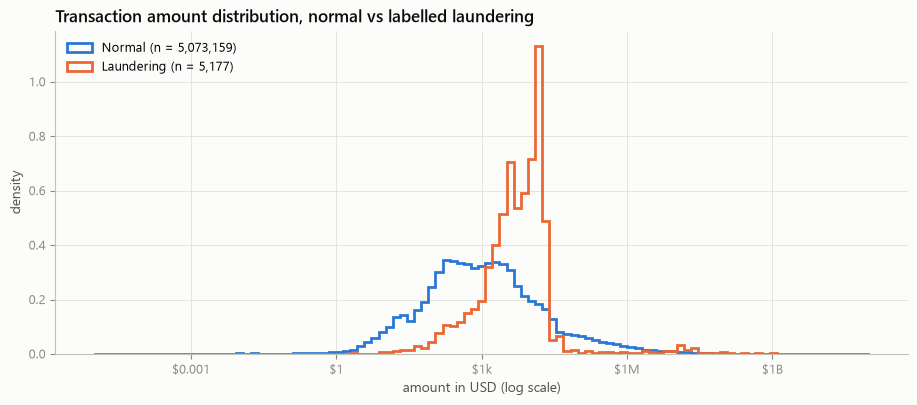

,count,mean,std,min,25%,50%,75%,99%,max
label,,,,,,,,,
Laundering,"5,177.00","5,169,484.75","231,331,508.65",0.39,"2,160.56","5,878.81","13,758.50","15,793,198.27","16,297,045,510.83"
Normal,"5,073,159.00","346,027.57","23,233,394.97",0.00,158.00,891.04,"5,273.88","3,099,715.32","26,558,612,904.53"


In [9]:
log_amt = np.log10(tx["amount_usd"])
bins = np.linspace(np.floor(log_amt.min()), np.ceil(log_amt.max()), 110)
fig, ax = plt.subplots(figsize=(11, 4.2))
for name, mask in (("Normal", y_all == 0), ("Laundering", y_all == 1)):
    ax.hist(log_amt[mask], bins=bins, density=True, histtype="step", lw=2,
            color=LABEL_COLORS[name], label=f"{name} (n = {int(mask.sum()):,})")
usd_log_ticks(ax)
ax.set_xlabel("amount in USD (log scale)")
ax.set_ylabel("density")
ax.set_title("Transaction amount distribution, normal vs labelled laundering")
ax.legend(loc="upper left")
save(fig, "eda_amount_distribution")
display(tx.groupby(y_all.map({0: "Normal", 1: "Laundering"}))["amount_usd"]
          .describe(percentiles=[.25, .5, .75, .99]).style.format("{:,.2f}"))

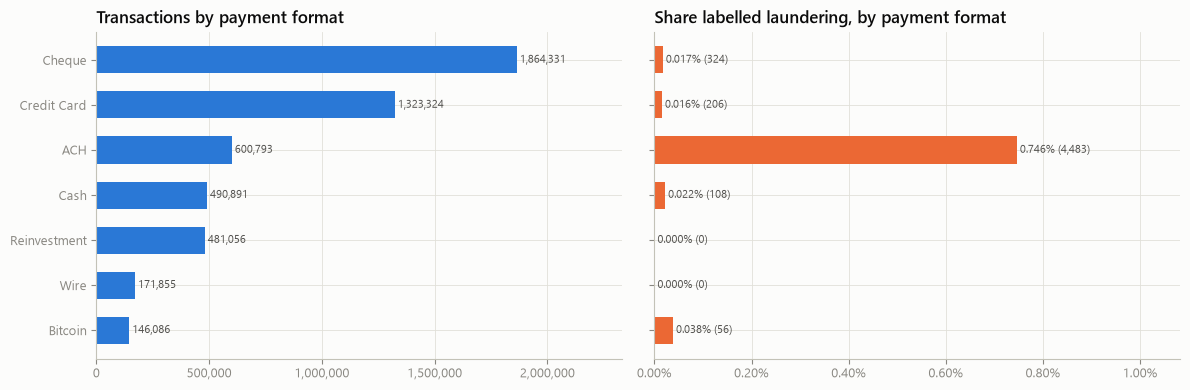

,rows,laundering,rate
payment_format,,,
Cheque,"1,864,331",324,0.0174
Credit Card,"1,323,324",206,0.0156
ACH,"600,793","4,483",0.7462
Cash,"490,891",108,0.0220
Reinvestment,"481,056",0,0.0000
Wire,"171,855",0,0.0000
Bitcoin,"146,086",56,0.0383


In [10]:
pf = tx.groupby("payment_format").agg(rows=("label", "size"), laundering=("label", "sum")).sort_values("rows")
pf["rate"] = 100 * pf["laundering"] / pf["rows"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].barh(pf.index, pf["rows"], color=PAL["s1"], height=0.6)
axes[0].set_title("Transactions by payment format")
thousands(axes[0], "x")
for i, v in enumerate(pf["rows"]):
    axes[0].text(v, i, f" {v:,.0f}", va="center", fontsize=8, color=PAL["ink2"])
axes[1].barh(pf.index, pf["rate"], color=PAL["s2"], height=0.6)
axes[1].set_title("Share labelled laundering, by payment format")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.2f}%"))
for i, (v, n) in enumerate(zip(pf["rate"], pf["laundering"])):
    axes[1].text(v, i, f" {v:.3f}% ({n:,})", va="center", fontsize=8, color=PAL["ink2"])
axes[0].set_xlim(0, pf["rows"].max() * 1.25)
axes[1].set_xlim(0, pf["rate"].max() * 1.45)
fig.tight_layout()
save(fig, "eda_payment_format")
display(pf.sort_values("rows", ascending=False).style.format({"rows": "{:,}", "laundering": "{:,}", "rate": "{:.4f}"}))

,transactions sent per sender,transactions received per receiver
count,496999.0,420640.0
mean,10.22,12.07
std,290.28,13.39
min,1.0,1.0
50%,2.0,4.0
90%,29.0,31.0
99%,92.0,51.0
max,168672.0,1084.0


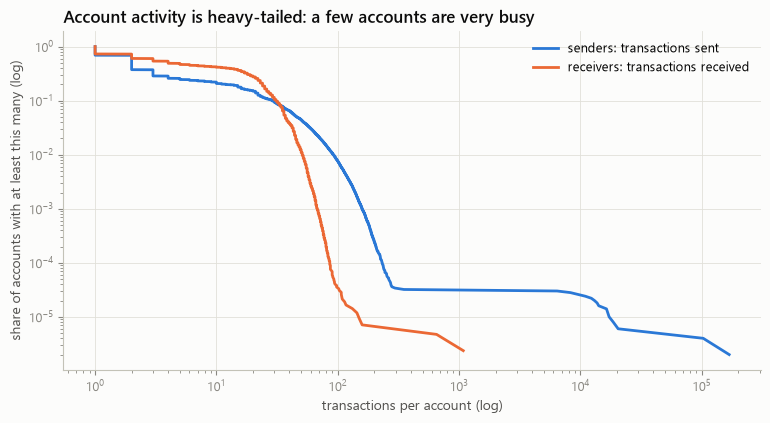

In [11]:
sent = tx["sender_id"].value_counts()
recv = tx["receiver_id"].value_counts()
display(pd.DataFrame({"transactions sent per sender": sent.describe(percentiles=[.5, .9, .99]),
                      "transactions received per receiver": recv.describe(percentiles=[.5, .9, .99])}).round(2))

fig, ax = plt.subplots(figsize=(9, 4.4))
for name, s, col in (("senders: transactions sent", sent, PAL["s1"]),
                     ("receivers: transactions received", recv, PAL["s2"])):
    k = np.sort(s.to_numpy())
    ccdf = 1.0 - np.arange(len(k)) / len(k)
    ax.loglog(k, ccdf, color=col, lw=2, label=name)
ax.set_xlabel("transactions per account (log)")
ax.set_ylabel("share of accounts with at least this many (log)")
ax.set_title("Account activity is heavy-tailed: a few accounts are very busy")
ax.legend()
save(fig, "eda_account_activity_ccdf")

In [12]:
p99 = tx["amount_usd"].quantile(0.99)
hv = tx["amount_usd"] >= p99
display(pd.DataFrame({
    "transactions": [int(hv.sum()), int((~hv).sum())],
    "laundering": [int(y_all[hv].sum()), int(y_all[~hv].sum())],
    "laundering_rate_%": [100 * y_all[hv].mean(), 100 * y_all[~hv].mean()]},
    index=[f"top 1% by amount (>= USD {p99:,.0f})", "remaining 99%"]).round(4))
print("Ten largest transactions (USD equivalent):")
display(tx.nlargest(10, "amount_usd")[["transaction_reference", "timestamp", "sender_id", "receiver_id",
                                        "amount_paid", "payment_currency", "amount_usd", "payment_format", "label"]])

,transactions,laundering,laundering_rate_%
"top 1% by amount (>= USD 3,101,511)",50784,100,0.1969
remaining 99%,5027552,5077,0.1010


Ten largest transactions (USD equivalent):


,transaction_reference,timestamp,sender_id,receiver_id,amount_paid,payment_currency,amount_usd,payment_format,label
3241870,HI-Small-03248642,2022-09-06 23:37:00,0136334|80D81A180,0235551|80D8816E0,1.499632e+11,Brazil Real,2.655861e+10,ACH,0
781351,HI-Small-00780797,2022-09-01 14:03:00,001|801ABB8F0,002454|801ABEBC0,1.662061e+10,US Dollar,1.662061e+10,ACH,0
2810043,HI-Small-02809337,2022-09-06 01:28:00,0024922|8096BB9C0,0213|8096D4300,2.150069e+10,Canadian Dollar,1.629705e+10,ACH,1
651909,HI-Small-00652516,2022-09-01 10:12:00,005365|80240ED60,00410|80240F230,1.346399e+10,Euro,1.577688e+10,ACH,0
3429771,HI-Small-03437494,2022-09-07 08:30:00,0112064|804C1CD70,007|804C41AB0,9.659333e+11,Rupee,1.315197e+10,ACH,0
3128990,HI-Small-03130044,2022-09-06 17:49:00,019925|803D95360,0210185|803DA4620,1.046302e+12,Yen,9.926967e+09,ACH,0
1086731,HI-Small-01091366,2022-09-01 23:10:00,01502|802A0AFD0,001024|813FEF230,7.009740e+09,Euro,8.213897e+09,Cheque,0
1714041,HI-Small-01711894,2022-09-02 18:56:00,022164|800E8B7F0,022164|800E8B7F0,8.046315e+09,US Dollar,8.046315e+09,ACH,0
4459246,HI-Small-04466474,2022-09-09 08:37:00,022164|800E8B7F0,022164|800E8B7F0,8.046315e+09,US Dollar,8.046315e+09,ACH,0
1714042,HI-Small-01711895,2022-09-02 18:56:00,022164|800E8B7F0,0116425|8060CEE00,6.260355e+11,Ruble,8.046315e+09,Cheque,0


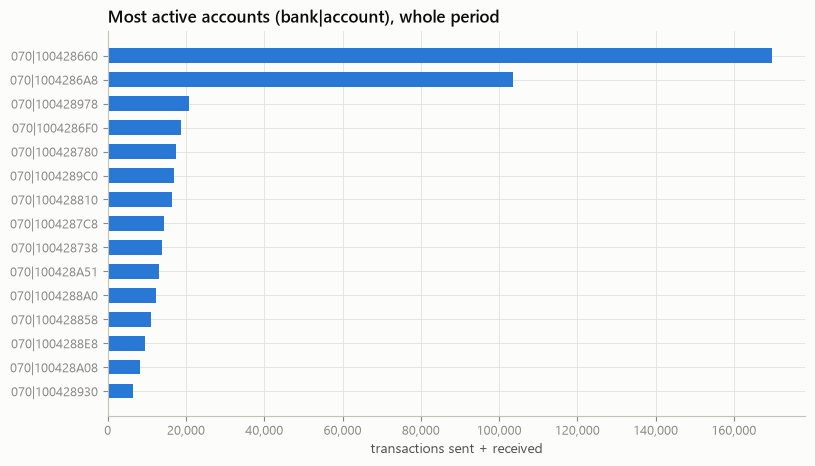

In [13]:
activity = (pd.concat([tx["sender_id"], tx["receiver_id"]]).value_counts().head(15)
              .rename("transactions (sent + received)"))
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(activity.index[::-1], activity.values[::-1], color=PAL["s1"], height=0.6)
thousands(ax, "x")
ax.set_title("Most active accounts (bank|account), whole period")
ax.set_xlabel("transactions sent + received")
save(fig, "eda_most_active_accounts")

## 5. Restricting to the modelled period
From here on only the warm-up, train, validation and test days are used. Labels go into the separate array `y`.

In [14]:
modelled = tx[tx["split"] != "excluded"].reset_index(drop=True)
del tx, y_all, accounts_all, log_amt
y = modelled["label"].astype(int).to_numpy()          # evaluation only
split = modelled["split"].to_numpy()
idx_train = np.flatnonzero(split == "train")
idx_val = np.flatnonzero(split == "validation")
idx_test = np.flatnonzero(split == "test")
print(f"modelled rows {len(modelled):,} | train {len(idx_train):,} | validation {len(idx_val):,} | test {len(idx_test):,}")

modelled rows 5,077,228 | train 2,134,000 | validation 965,521 | test 862,788


## 6. Transaction feature engineering  &  8. Graph feature engineering
Both feature groups come from a single call to `services.feature_engineering.compute_features`.
History features use the trailing window **[m − 1440, m − 1] minutes**:
* Transactions in the same minute are invisible to each other.
* Future transactions are never used.
* The label is never read.

A fixed 24-hour window was chosen over running totals since Sep 1. Running totals grow every day, so validation and test
transactions would look abnormal simply because they come later (feature version 1 showed the median sender count going
16 → 35 → 39 across train/validation/test). The 24h window keeps the splits comparable (table below).

The graph features are defined on the directed transaction multigraph of the window:
* **in/out-degree** = distinct counterparties, excluding the account itself;
* **counterparties** = distinct partners in either direction;
* **transaction count** and **volume** = every edge in or out. A self-transfer counts once in each direction.

In [15]:
t0 = time.perf_counter()
F = fe.compute_features(modelled, fx)
print(f"features for {len(F):,} transactions in {time.perf_counter() - t0:.1f}s; "
      f"missing values: {int(F.isna().sum().sum())}")
assert "label" not in F.columns and len(F) == len(modelled)
schema = pd.DataFrame(fe.FEATURE_SCHEMA)[["name", "group", "kind", "transform", "description"]]
schema["used by"] = np.where(schema["group"] == "graph", "Model 2", "Models 1 + 2")
display(schema)
display(F.head(5))

features for 5,077,228 transactions in 21.4s; missing values: 0


,name,group,kind,transform,description,used by
0,amount_usd,transaction,numeric,log1p,"Amount paid, converted to US Dollar with datas...",Models 1 + 2
1,hour,transaction,numeric,NaN,Hour of day (0-23) of the transaction,Models 1 + 2
2,payment_format,transaction,categorical,onehot,Transaction type / payment format,Models 1 + 2
3,payment_currency,transaction,categorical,onehot,Currency the sender paid in,Models 1 + 2
4,is_cross_currency,transaction,binary,NaN,1 if paid and received currencies differ,Models 1 + 2
5,is_self_transfer,transaction,binary,NaN,1 if sender and receiver are the same account,Models 1 + 2
6,sender_out_count_24h,transaction,numeric,log1p,Transactions sent by the sender in the previou...,Models 1 + 2
7,receiver_in_count_24h,transaction,numeric,log1p,Transactions received by the receiver in the p...,Models 1 + 2
8,sender_amount_deviation_24h,transaction,numeric,NaN,log(1+amount) minus the mean log(1+amount) of ...,Models 1 + 2
9,sender_amount_std_24h,transaction,numeric,NaN,Std of log(1+amount) of the sender's payments ...,Models 1 + 2


,amount_usd,hour,payment_format,payment_currency,is_cross_currency,is_self_transfer,sender_out_count_24h,receiver_in_count_24h,sender_amount_deviation_24h,sender_amount_std_24h,pair_count_24h,sender_in_degree_24h,sender_out_degree_24h,receiver_in_degree_24h,receiver_out_degree_24h,sender_counterparties_24h,receiver_counterparties_24h,sender_txn_count_24h,receiver_txn_count_24h,sender_volume_24h,receiver_volume_24h
0,14675.57,0,Reinvestment,US Dollar,0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,897.37,0,Reinvestment,US Dollar,0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,99986.94,0,Reinvestment,US Dollar,0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,16.08,0,Reinvestment,US Dollar,0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,10.30,0,Reinvestment,US Dollar,0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [16]:
# Leakage / consistency spot-check on the full data: score one hour of the test period
# against a separately built 24h history tail; it must equal the one-pass features.
probe_start = pd.Timestamp("2022-09-09 12:00")
pm = ((modelled["timestamp"] >= probe_start) & (modelled["timestamp"] < probe_start + pd.Timedelta(hours=1))).to_numpy()
hist = fe.history_tail(modelled[modelled["timestamp"] < probe_start])
F_probe = fe.compute_features(modelled[pm], fx, history=hist)
num_cols = [f["name"] for f in fe.FEATURE_SCHEMA if f["kind"] != "categorical"]
rel = ((F_probe[num_cols] - F.loc[pm, num_cols]).abs() / (F.loc[pm, num_cols].abs() + 1)).max().max()
assert (F_probe[["payment_format", "payment_currency"]].values == F.loc[pm, ["payment_format", "payment_currency"]].values).all()
print(f"{int(pm.sum()):,} probe transactions; history rows {len(hist):,}; max relative difference {rel:.2e}")
assert rel < 1e-9

drift = F[num_cols].assign(split=split).groupby("split").median().T[["warmup", "train", "validation", "test"]]
display(drift.style.format("{:,.2f}").set_caption("Median feature value per split (warm-up has no full 24h history yet)"))

26,704 probe transactions; history rows 569,614; max relative difference 9.92e-10


split,warmup,train,validation,test
amount_usd,"1,333.92",863.92,801.56,755.51
hour,7.00,11.00,11.00,11.00
is_cross_currency,0.00,0.00,0.00,0.00
is_self_transfer,0.00,0.00,0.00,0.00
sender_out_count_24h,1.00,4.00,5.00,4.00
receiver_in_count_24h,1.00,2.00,2.00,2.00
sender_amount_deviation_24h,0.00,0.00,0.00,0.00
sender_amount_std_24h,0.00,1.14,1.19,1.03
pair_count_24h,0.00,1.00,2.00,1.00
sender_in_degree_24h,0.00,1.00,1.00,1.00


## 7. Financial transaction graph construction (NetworkX)
* Accounts are nodes. Each transaction is its own directed edge (`MultiDiGraph`), so repeated payments between
  the same accounts stay as separate edges with their own amount, time and reference.
* The full period has about 5 million edges, so the descriptive graph uses a bounded window (3 hours in quick
  mode, one day in full mode) instead of the whole network.

In [17]:
GRAPH_WINDOW = (("2022-09-05 09:00", "2022-09-05 12:00") if RUN_MODE == "quick"
                else ("2022-09-05 00:00", "2022-09-06 00:00"))
gw = modelled[(modelled["timestamp"] >= GRAPH_WINDOW[0]) & (modelled["timestamp"] < GRAPH_WINDOW[1])]
t0 = time.perf_counter()
G = fe.build_transaction_graph(gw, fx)
D = nx.DiGraph(G)                                   # distinct directed relationships
D.remove_edges_from(list(nx.selfloop_edges(D)))
wcc = sorted((len(c) for c in nx.weakly_connected_components(G)), reverse=True)
graph_stats = pd.Series({
    "window": f"{GRAPH_WINDOW[0]} -> {GRAPH_WINDOW[1]}",
    "accounts (nodes)": f"{G.number_of_nodes():,}",
    "transactions (edges)": f"{G.number_of_edges():,}",
    "distinct sender->receiver relationships": f"{D.number_of_edges():,}",
    "edges on repeated relationships": f"{G.number_of_edges() - nx.DiGraph(G).number_of_edges():,}",
    "self-transfer edges": f"{nx.number_of_selfloops(G):,}",
    "weakly connected components": f"{len(wcc):,}",
    "largest component (accounts)": f"{wcc[0]:,} ({100 * wcc[0] / G.number_of_nodes():.1f}%)",
    "density (distinct relationships)": f"{nx.density(D):.2e}",
    "build time": f"{time.perf_counter() - t0:.1f}s",
}, name="value").to_frame()
display(graph_stats)

acct = pd.DataFrame({
    "in_degree": dict(D.in_degree()), "out_degree": dict(D.out_degree()),
    "transactions": dict(G.degree()),
    "volume_usd": pd.Series(dict(G.in_degree(weight="amount_usd"))) + pd.Series(dict(G.out_degree(weight="amount_usd"))),
}).fillna(0)
acct["unique_counterparties"] = [len(set(D.predecessors(n)) | set(D.successors(n))) for n in acct.index]
print("Most connected accounts in the window:")
display(acct.sort_values("unique_counterparties", ascending=False).head(10)
            .style.format({"volume_usd": "{:,.0f}"}))
pairs = pd.Series([(u, v) for u, v, _ in G.edges(keys=True) if u != v]).value_counts().head(10)
print("Most frequently repeated relationships (sender -> receiver: transactions):")
display(pairs.rename("transactions").to_frame())

,value
window,2022-09-05 09:00 -> 2022-09-05 12:00
accounts (nodes),"46,176"
transactions (edges),"58,767"
distinct sender->receiver relationships,"27,692"
edges on repeated relationships,"30,439"
self-transfer edges,"1,319"
weakly connected components,"18,485"
largest component (accounts),"1,377 (3.0%)"
density (distinct relationships),1.30e-05
build time,0.7s


Most connected accounts in the window:


,in_degree,out_degree,transactions,volume_usd,unique_counterparties
070|100428660,0,1174,2365,"293,317,549",1174
070|1004286A8,0,760,1513,"441,786,200",760
070|1004286F0,0,145,270,"47,082,857",145
070|100428978,0,140,261,"91,231,540",140
070|100428780,0,130,265,"23,190,001",130
070|100428810,0,123,249,"39,818,677",123
070|1004289C0,0,100,197,"4,780,889",100
070|100428738,0,98,195,"7,571,047",98
070|1004288A0,0,96,188,"14,972,788",96
070|1004287C8,0,92,184,"7,974,898",92


Most frequently repeated relationships (sender -> receiver: transactions):


,transactions
"(070|100428660, 0017748|8072EE6F0)",5
"(070|100428660, 0128684|80D469DF0)",5
"(00513|802FB7770, 029404|80B58CE70)",5
"(001|8048FC2C0, 002627|80B58BB40)",5
"(0210404|805448AC0, 0123288|80D0D58D0)",5
"(006075|8066DE200, 0234347|80DD25950)",5
"(01502|801585180, 016871|8033D3080)",5
"(012797|80B306D50, 0018049|814676E00)",5
"(018067|803007E10, 014|8031E1140)",5
"(070|100428780, 0015385|805996090)",5


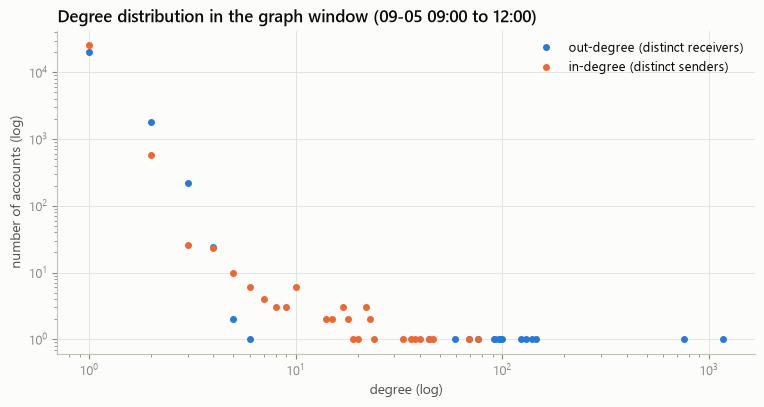

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for name, col, c in (("out-degree (distinct receivers)", "out_degree", PAL["s1"]),
                     ("in-degree (distinct senders)", "in_degree", PAL["s2"])):
    vc = acct[col][acct[col] > 0].value_counts().sort_index()
    ax.loglog(vc.index, vc.values, marker="o", ms=4, lw=0, color=c, label=name)
ax.set_xlabel("degree (log)")
ax.set_ylabel("number of accounts (log)")
ax.set_title(f"Degree distribution in the graph window ({GRAPH_WINDOW[0][5:]} to {GRAPH_WINDOW[1][11:]})")
ax.legend()
save(fig, "graph_degree_distribution")

**Representative subgraph.** This shows the neighbourhood of an account that sends labelled-laundering transactions inside the
window. Orange edges are labelled laundering. The labels are used for highlighting in this picture only.

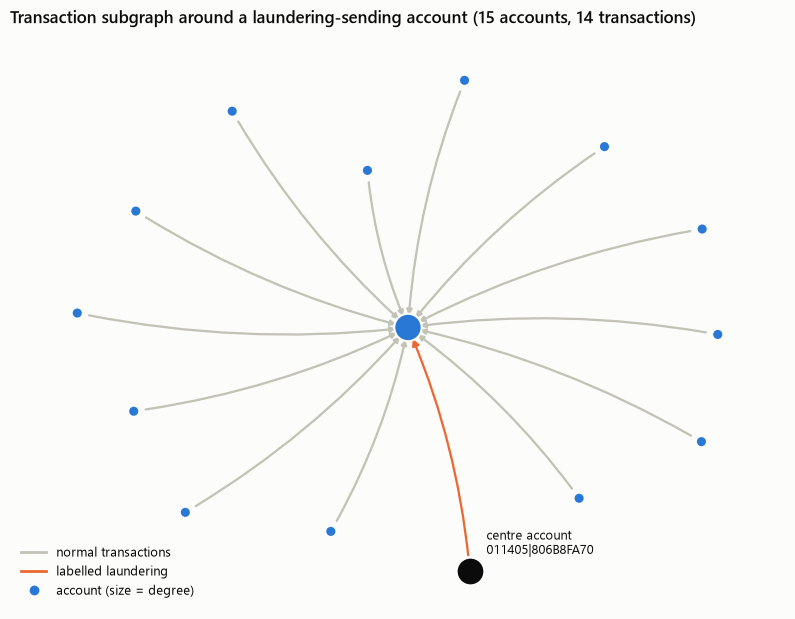

interactive graph: outputs\graphs\representative_subgraph.html


In [19]:
edge_label = dict(zip(gw["transaction_reference"], gw["label"]))
cands = gw.loc[gw["label"] == 1, "sender_id"].value_counts().index.tolist()
center = None
for cand in cands:
    E = nx.ego_graph(G, cand, radius=2, undirected=True)
    if 12 <= E.number_of_nodes() <= 70:
        center = cand
        break
if center is None:                                 # fall back to the 1-hop neighbourhood, capped
    center = cands[0] if cands else acct["transactions"].idxmax()
    nb = sorted(set(G.predecessors(center)) | set(G.successors(center)),
                key=lambda n: -G.degree(n))[:59]
    E = G.subgraph([center, *nb]).copy()
S = nx.DiGraph()
for u, v, d in E.edges(data=True):
    if u == v:
        continue
    w = S.get_edge_data(u, v, {"count": 0, "laundering": 0})
    S.add_edge(u, v, count=w["count"] + 1, laundering=w["laundering"] + edge_label.get(d["reference"], 0))
S.add_nodes_from(E.nodes())
pos = nx.spring_layout(S.to_undirected(), seed=SEED, k=0.9)

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
for side in ax.spines.values():
    side.set_visible(False)
norm_e = [(u, v) for u, v, d in S.edges(data=True) if d["laundering"] == 0]
laund_e = [(u, v) for u, v, d in S.edges(data=True) if d["laundering"] > 0]
widths = lambda es: [0.8 + 1.2 * np.log1p(S[u][v]["count"]) for u, v in es]
nx.draw_networkx_edges(S, pos, edgelist=norm_e, width=widths(norm_e), edge_color=PAL["axis"],
                       arrowsize=8, ax=ax, connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edges(S, pos, edgelist=laund_e, width=widths(laund_e), edge_color=PAL["s2"],
                       arrowsize=10, ax=ax, connectionstyle="arc3,rad=0.08")
others = [n for n in S if n != center]
nx.draw_networkx_nodes(S, pos, nodelist=others, node_size=[40 + 25 * S.degree(n) for n in others],
                       node_color=PAL["s1"], edgecolors=PAL["surface"], linewidths=1.5, ax=ax)
nx.draw_networkx_nodes(S, pos, nodelist=[center], node_size=420, node_color=PAL["ink"],
                       edgecolors=PAL["surface"], linewidths=2, ax=ax)
ax.annotate(f"centre account\n{center}", pos[center], xytext=(12, 12), textcoords="offset points",
            fontsize=9, color=PAL["ink"])
ax.legend(handles=[Line2D([], [], color=PAL["axis"], lw=2, label="normal transactions"),
                   Line2D([], [], color=PAL["s2"], lw=2, label="labelled laundering"),
                   Line2D([], [], marker="o", lw=0, color=PAL["s1"], label="account (size = degree)")],
          loc="lower left")
ax.set_title(f"Transaction subgraph around a laundering-sending account "
             f"({S.number_of_nodes()} accounts, {E.number_of_edges()} transactions)")
save(fig, "graph_representative_subgraph")

# interactive version
ex, ey, lx, ly = [], [], [], []
for u, v in S.edges():
    xs, ys = (lx, ly) if S[u][v]["laundering"] else (ex, ey)
    xs += [pos[u][0], pos[v][0], None]; ys += [pos[u][1], pos[v][1], None]
fig_i = go.Figure()
fig_i.add_trace(go.Scatter(x=ex, y=ey, mode="lines", line=dict(color=PAL["axis"], width=1.5),
                           name="normal", hoverinfo="skip"))
fig_i.add_trace(go.Scatter(x=lx, y=ly, mode="lines", line=dict(color=PAL["s2"], width=2.5),
                           name="labelled laundering", hoverinfo="skip"))
nodes = list(S.nodes())
fig_i.add_trace(go.Scatter(
    x=[pos[n][0] for n in nodes], y=[pos[n][1] for n in nodes], mode="markers", name="account",
    marker=dict(size=[18 if n == center else 8 + 2 * S.degree(n) for n in nodes],
                color=[PAL["ink"] if n == center else PAL["s1"] for n in nodes],
                line=dict(color=PAL["surface"], width=1.5)),
    text=[f"{n}<br>in-degree {S.in_degree(n)}, out-degree {S.out_degree(n)}" for n in nodes],
    hoverinfo="text"))
fig_i.update_layout(title="CoDetect - transaction subgraph (hover for accounts)", template="plotly_white",
                    showlegend=True, xaxis=dict(visible=False), yaxis=dict(visible=False),
                    plot_bgcolor=PAL["surface"], paper_bgcolor=PAL["surface"])
fig_i.write_html(C.GRAPHS_DIR / "representative_subgraph.html", include_plotlyjs="cdn")
print("interactive graph:", (C.GRAPHS_DIR / "representative_subgraph.html").relative_to(ROOT))

**Bounded account-relationship similarity (illustration).** This is the Jaccard similarity of the counterparty sets of the
15 most connected accounts in the window. It is deliberately small; a dense all-account matrix is never built.

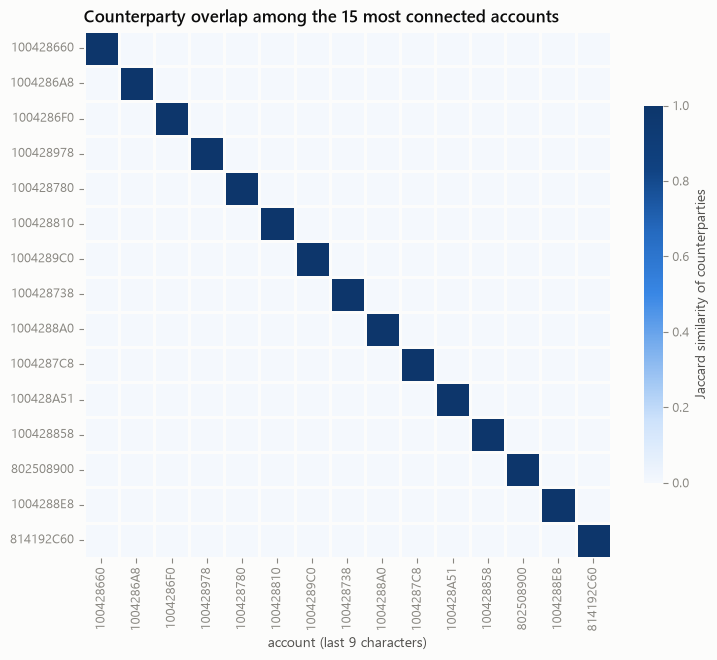

In [20]:
top = acct.sort_values("unique_counterparties", ascending=False).head(15).index
nbrs = {a: set(D.predecessors(a)) | set(D.successors(a)) for a in top}
J = pd.DataFrame([[len(nbrs[a] & nbrs[b]) / max(len(nbrs[a] | nbrs[b]), 1) for b in top] for a in top],
                 index=[a[-9:] for a in top], columns=[a[-9:] for a in top])
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(J, cmap=SEQ, vmin=0, vmax=1, square=True, linewidths=1, linecolor=PAL["surface"],
            cbar_kws={"label": "Jaccard similarity of counterparties", "shrink": 0.7}, ax=ax)
ax.set_title("Counterparty overlap among the 15 most connected accounts")
ax.set_xlabel("account (last 9 characters)"); ax.set_ylabel("")
save(fig, "graph_similarity_matrix")

### 8.1 Graph features vs NetworkX
For a few query minutes, the 24h history graph is built with NetworkX and its features are recomputed directly.
They must match the vectorised features exactly (the unit tests check the same thing on real subsets).

In [21]:
check_minutes = np.sort(rng.choice(modelled.loc[idx_val, "minute"].unique(), size=2, replace=False))
mism, checked = 0, 0
for m in check_minutes:
    Gm = fe.window_graph(modelled, fx, int(m))
    rows = np.flatnonzero(modelled["minute"].to_numpy() == m)[:15]
    for i in rows:
        ref = fe.graph_features_networkx(Gm, modelled.at[i, "sender_id"], modelled.at[i, "receiver_id"])
        for k, v in ref.items():
            checked += 1
            mism += not np.isclose(F.at[i, k], v, rtol=1e-9, atol=1e-6)
    del Gm
print(f"{checked} feature values compared against NetworkX at {len(check_minutes)} minutes: {mism} mismatches")
assert mism == 0

330 feature values compared against NetworkX at 2 minutes: 0 mismatches


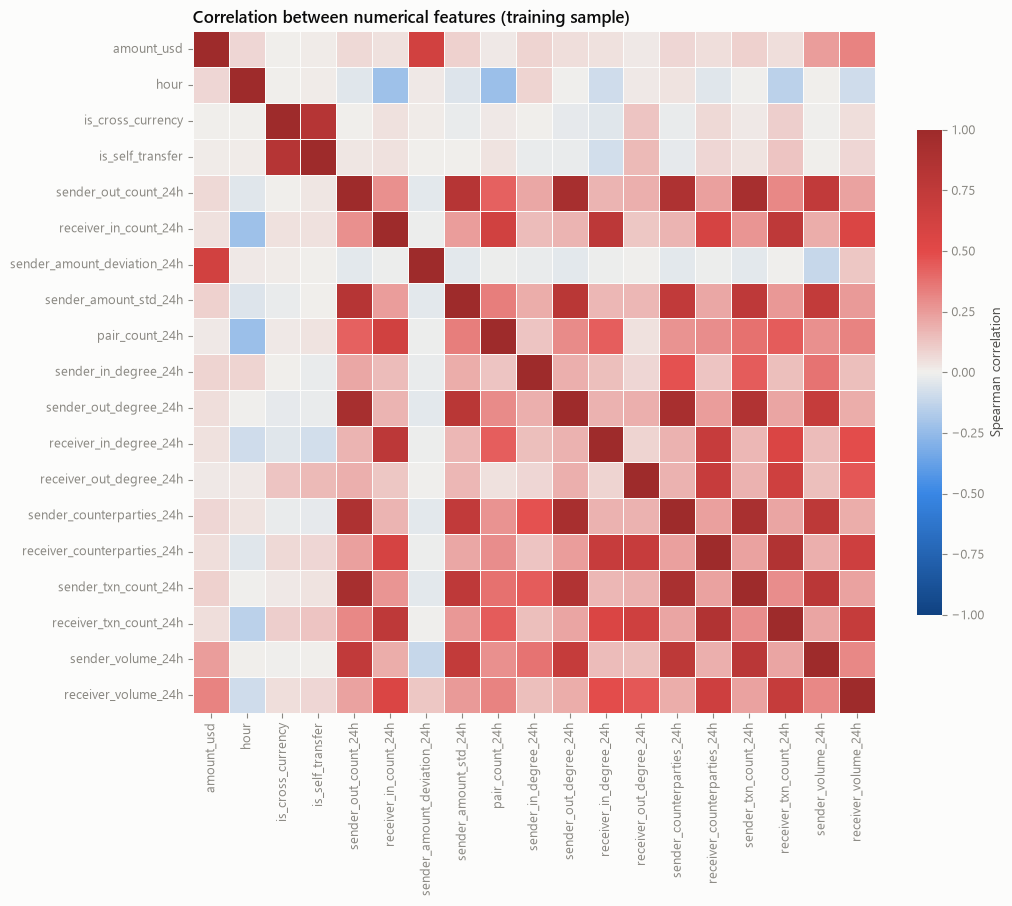

In [22]:
sample_idx = rng.choice(idx_train, size=min(150_000, len(idx_train)), replace=False)
corr = F.iloc[sample_idx][num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=DIV, vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            linecolor=PAL["surface"], cbar_kws={"label": "Spearman correlation", "shrink": 0.7}, ax=ax)
ax.set_title("Correlation between numerical features (training sample)")
save(fig, "features_correlation")

## 9. Model 1: transaction-only Isolation Forest  &  10. Model 2: graph-enhanced Isolation Forest
* **Preprocessing** (fitted on training rows only): `log1p` + standardisation for skewed counts and amounts,
  and standardisation for the other numerics. Payment format, currency and the two flags are handled by one of the
  three candidate encodings below.
* **Training data:** training-period rows without labels. This is fully unsupervised, so the few laundering rows in the
  training days are not removed; a real deployment would not know which they are.
* **Search, the same for both models:** 3 encodings × 4 settings (`max_samples` × `max_features`, 200 trees). The
  combination with the best **validation PR-AUC** is kept, so each model ends with one configuration.

| Encoding | Payment format / currency | Cross-currency & self-transfer flags |
|---|---|---|
| `onehot` | one-hot columns | 0/1 |
| `frequency` | training frequency of the value | 0/1 |
| `numeric_only` | not used | not used |

> **Revision note (transparency).** The first version of this notebook used `onehot` only.
> Its validation results showed a structural weakness. Isolation Forest isolates *rare values* in low-cardinality
> columns first, so rare currencies, cross-currency payments and self-transfers filled the top of the ranking.
> Labelled laundering looks ordinary on exactly those columns: 0 cross-currency, almost no self-transfers, mostly ACH.
> The Critical level held 0 laundering transactions in both models.
>
> That first version **had already scored the test days once** before the run was stopped. Those test results were
> archived **unopened** in `outputs/archive/v1_onehot/`. The encoding search was then added, decided from validation
> evidence only. Both versions' test results are reported in Section 16.

In [23]:
N_ESTIMATORS = 200
GRID = [dict(max_samples=256, max_features=1.0), dict(max_samples=256, max_features=0.6),
        dict(max_samples=2048, max_features=1.0), dict(max_samples=2048, max_features=0.6)]
n_fit = MODE["train_sample_rows"]
idx_fit = (np.sort(rng.choice(idx_train, size=n_fit, replace=False))
           if n_fit and n_fit < len(idx_train) else idx_train)
y_val, y_test = y[idx_val], y[idx_test]
print(f"fitting rows: {len(idx_fit):,} of {len(idx_train):,} training rows "
      f"({int(y[idx_fit].sum())} of them labelled laundering - not used)")

def train_model(name):
    feats = md.MODEL_FEATURES[name]
    F_fit, F_val = F.iloc[idx_fit][feats], F.iloc[idx_val][feats]
    rows, best = [], None
    for enc in md.ENCODINGS:
        pre = md.build_preprocessor(feats, enc).fit(F_fit)
        X_fit, X_val = pre.transform(F_fit), pre.transform(F_val)
        for i, cfg in enumerate(GRID):
            t0 = time.perf_counter()
            m = md.fit_isolation_forest(X_fit, n_estimators=N_ESTIMATORS, seed=SEED, **cfg)
            s = md.raw_anomaly_score(m, X_val)
            row = {"model": md.MODEL_LABELS[name], "encoding": enc, "config": i, **cfg,
                   "encoded_columns": X_fit.shape[1],
                   "val_pr_auc": average_precision_score(y_val, s), "val_roc_auc": roc_auc_score(y_val, s),
                   "seconds": round(time.perf_counter() - t0, 1)}
            rows.append(row)
            if best is None or row["val_pr_auc"] > best["row"]["val_pr_auc"]:
                best = {"row": row, "model": m, "pre": pre, "val_raw": s,
                        "fit_raw": md.raw_anomaly_score(m, X_fit)}
    r = best["row"]
    print(f"{md.MODEL_LABELS[name]}: selected encoding '{r['encoding']}', config {r['config']} "
          f"({r['encoded_columns']} encoded columns)")
    return {"pre": best["pre"], "model": best["model"], "encoding": r["encoding"],
            "input_features": md.input_features(feats, r["encoding"]),
            "config": {k: r[k] for k in ("max_samples", "max_features")},
            "val_raw": best["val_raw"], "fit_raw": best["fit_raw"],
            "grid": pd.DataFrame(rows), "encoded_features": list(best["pre"].get_feature_names_out())}

trained = {}

fitting rows: 300,000 of 2,134,000 training rows (316 of them labelled laundering - not used)


In [24]:
trained["transaction_only"] = train_model("transaction_only")
display(trained["transaction_only"]["grid"].style.format({"val_pr_auc": "{:.4f}", "val_roc_auc": "{:.4f}"}))

Transaction-only IF: selected encoding 'onehot', config 0 (30 encoded columns)


,model,encoding,config,max_samples,max_features,encoded_columns,val_pr_auc,val_roc_auc,seconds
0,Transaction-only IF,onehot,0,256,1.000000,30,0.0013,0.6248,7.300000
1,Transaction-only IF,onehot,1,256,0.600000,30,0.0013,0.6062,21.900000
2,Transaction-only IF,onehot,2,2048,1.000000,30,0.0013,0.5912,10.500000
3,Transaction-only IF,onehot,3,2048,0.600000,30,0.0012,0.5719,27.100000
4,Transaction-only IF,frequency,0,256,1.000000,11,0.0011,0.5565,8.600000
5,Transaction-only IF,frequency,1,256,0.600000,11,0.0012,0.5823,12.800000
6,Transaction-only IF,frequency,2,2048,1.000000,11,0.0012,0.5713,12.400000
7,Transaction-only IF,frequency,3,2048,0.600000,11,0.0011,0.5658,15.900000
8,Transaction-only IF,numeric_only,0,256,1.000000,7,0.0011,0.5402,8.300000
9,Transaction-only IF,numeric_only,1,256,0.600000,7,0.0010,0.5062,8.900000


In [25]:
trained["graph_enhanced"] = train_model("graph_enhanced")
display(trained["graph_enhanced"]["grid"].style.format({"val_pr_auc": "{:.4f}", "val_roc_auc": "{:.4f}"}))

Graph-enhanced IF: selected encoding 'numeric_only', config 1 (17 encoded columns)


,model,encoding,config,max_samples,max_features,encoded_columns,val_pr_auc,val_roc_auc,seconds
0,Graph-enhanced IF,onehot,0,256,1.000000,40,0.0016,0.6858,7.700000
1,Graph-enhanced IF,onehot,1,256,0.600000,40,0.0017,0.6890,28.000000
2,Graph-enhanced IF,onehot,2,2048,1.000000,40,0.0016,0.6666,10.300000
3,Graph-enhanced IF,onehot,3,2048,0.600000,40,0.0017,0.7017,30.900000
4,Graph-enhanced IF,frequency,0,256,1.000000,21,0.0016,0.6776,8.400000
5,Graph-enhanced IF,frequency,1,256,0.600000,21,0.0017,0.6978,19.000000
6,Graph-enhanced IF,frequency,2,2048,1.000000,21,0.0016,0.6792,11.700000
7,Graph-enhanced IF,frequency,3,2048,0.600000,21,0.0017,0.7000,19.800000
8,Graph-enhanced IF,numeric_only,0,256,1.000000,17,0.0017,0.6871,8.300000
9,Graph-enhanced IF,numeric_only,1,256,0.600000,17,0.0018,0.7008,10.000000


## 11. Anomaly scoring
* **raw score** = −`score_samples`, so a higher value means more abnormal.
* **anomaly score (0–100)** = the percentile of the raw score among **training-period** raw scores. A score of 99 means
  "more unusual than 99% of training transactions". It ranks rarity and is **not** a fraud probability.

The normalisation quantiles are saved and reused unchanged at inference.

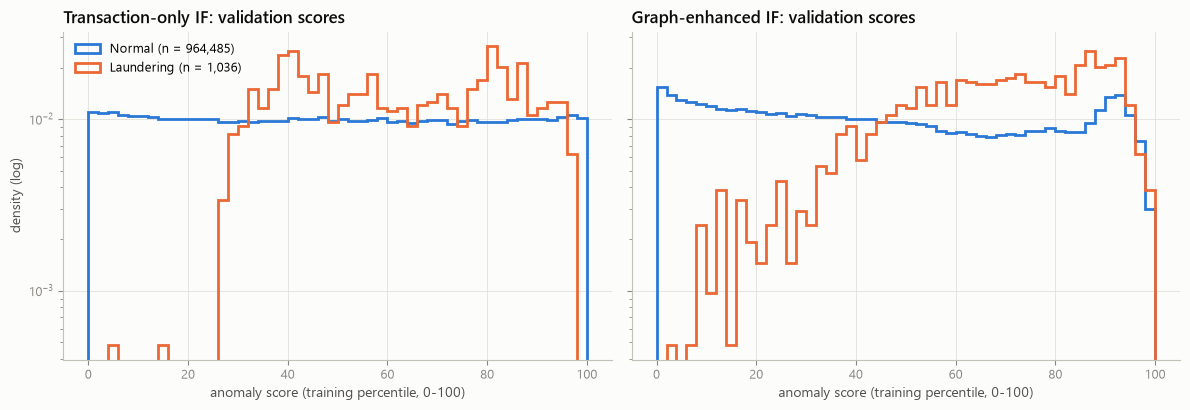

In [26]:
normalizers = {m: md.fit_score_normalizer(t["fit_raw"]) for m, t in trained.items()}
for m, t in trained.items():
    t["val_score"] = md.normalize_scores(t["val_raw"], normalizers[m])
    t["fit_score"] = md.normalize_scores(t["fit_raw"], normalizers[m])
    assert np.all(np.diff(t["val_score"][np.argsort(t["val_raw"])]) >= 0), "normalisation must be monotone"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
bins = np.linspace(0, 100, 51)
for ax, (m, t) in zip(axes, trained.items()):
    for name, mask in (("Normal", y_val == 0), ("Laundering", y_val == 1)):
        ax.hist(t["val_score"][mask], bins=bins, density=True, histtype="step", lw=2,
                color=LABEL_COLORS[name], label=f"{name} (n = {int(mask.sum()):,})")
    ax.set_title(f"{md.MODEL_LABELS[m]}: validation scores")
    ax.set_xlabel("anomaly score (training percentile, 0-100)")
    ax.set_yscale("log")
axes[0].set_ylabel("density (log)")
axes[0].legend(loc="upper left")
fig.tight_layout()
save(fig, "scores_distribution_validation")

## 12. Risk classification
The cut-points are percentiles of the training score distribution and work as an **alert budget**. They were not tuned on labels.

| Risk level | Anomaly score | Expected share of ordinary traffic |
|---|---|---|
| Low | < 90 | 90% |
| Medium | 90 – 97 | 7% |
| High | 97 – 99.5 | 2.5% |
| Critical | ≥ 99.5 | 0.5% |

**Suspicious** means High or Critical, about the top 3% most unusual transactions.
The table checks how these levels behave on validation, including the laundering rate per level.

,model,data,risk level,transactions,share_%,laundering,laundering_rate_%
0,Transaction-only IF,train (fitting rows),Low,"270,000",90.00,289,0.1070
1,Transaction-only IF,train (fitting rows),Medium,"21,000",7.00,23,0.1095
2,Transaction-only IF,train (fitting rows),High,"7,500",2.50,4,0.0533
3,Transaction-only IF,train (fitting rows),Critical,"1,500",0.50,0,0.0000
4,Transaction-only IF,validation,Low,"867,391",89.84,947,0.1092
5,Transaction-only IF,validation,Medium,"67,985",7.04,84,0.1236
6,Transaction-only IF,validation,High,"25,703",2.66,5,0.0195
7,Transaction-only IF,validation,Critical,"4,442",0.46,0,0.0000
8,Graph-enhanced IF,train (fitting rows),Low,"270,000",90.00,267,0.0989
9,Graph-enhanced IF,train (fitting rows),Medium,"21,000",7.00,34,0.1619


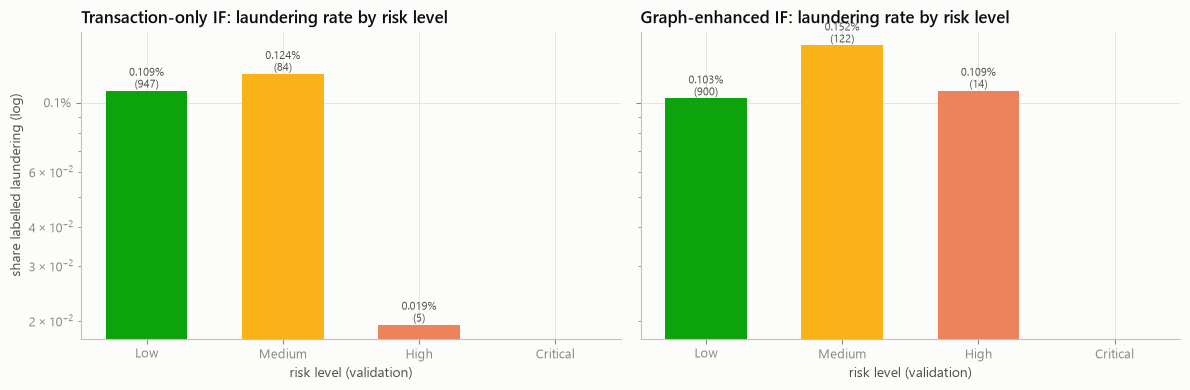

In [27]:
LEVELS = [n for n, _ in md.RISK_LEVELS]
risk_rows = []
for m, t in trained.items():
    for part, scores, labels in (("train (fitting rows)", t["fit_score"], y[idx_fit]),
                                 ("validation", t["val_score"], y_val)):
        lv = md.risk_level(scores)
        for L in LEVELS:
            mask = lv == L
            risk_rows.append({"model": md.MODEL_LABELS[m], "data": part, "risk level": L,
                              "transactions": int(mask.sum()), "share_%": 100 * mask.mean(),
                              "laundering": int(labels[mask].sum()),
                              "laundering_rate_%": 100 * labels[mask].mean() if mask.any() else np.nan})
risk_tbl = pd.DataFrame(risk_rows)
display(risk_tbl.style.format({"share_%": "{:.2f}", "laundering_rate_%": "{:.4f}", "transactions": "{:,}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, m in zip(axes, trained):
    r = risk_tbl[(risk_tbl["model"] == md.MODEL_LABELS[m]) & (risk_tbl["data"] == "validation")]
    bars = ax.bar(r["risk level"], r["laundering_rate_%"], color=[RISK_COLORS[L] for L in r["risk level"]], width=0.6)
    for b, v, n in zip(bars, r["laundering_rate_%"], r["laundering"]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}%\n({n:,})", ha="center", va="bottom",
                fontsize=8, color=PAL["ink2"])
    ax.set_title(f"{md.MODEL_LABELS[m]}: laundering rate by risk level")
    ax.set_yscale("log")
    ax.set_xlabel("risk level (validation)")
axes[0].set_ylabel("share labelled laundering (log)")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}%"))
fig.tight_layout()
save(fig, "risk_levels_validation")

## 13. Anomaly feature detection: which features are abnormal?
Each feature value of a flagged transaction is compared with the **training reference distribution**:
* **numeric:** tail probability = min(P(X ≤ x), P(X ≥ x));
* **categorical:** the category's frequency in training;
* **abnormality** = −log10(tail probability). A score of 3 means "a value this extreme occurs in about 1 in 1,000 training transactions".

The top three features per Suspicious transaction are reported with a plain-language sentence.
They are **abnormal indicators**. They describe what is unusual and do **not** prove why a transaction is or isn't laundering.

In [28]:
feature_reference = md.fit_feature_reference(F.iloc[idx_fit], fe.ALL_FEATURES, seed=SEED)

## 14. Model evaluation on the validation period
Both models are evaluated on **the same validation transactions**. Laundering is rare (about 0.1%), so PR-AUC is the
main measure: a random ranking scores roughly the prevalence. ROC-AUC is shown for completeness.
Precision, recall and F1 are reported at the Suspicious cut-point (score ≥ 97) and the Critical cut-point (score ≥ 99.5).

In [29]:
HIGH_CUT, CRIT_CUT = dict(md.RISK_LEVELS)["High"], dict(md.RISK_LEVELS)["Critical"]

def at_cut(y_true, score, cut):
    pred = score >= cut
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "flagged": int(pred.sum()), "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}

def evaluate(name, y_true, raw, score, part):
    row = {"model": md.MODEL_LABELS[name], "data": part, "transactions": len(y_true),
           "laundering": int(y_true.sum()), "prevalence": y_true.mean(),
           "pr_auc": average_precision_score(y_true, raw), "roc_auc": roc_auc_score(y_true, raw)}
    row.update({f"suspicious_{k}": v for k, v in at_cut(y_true, score, HIGH_CUT).items()})
    row.update({f"critical_{k}": v for k, v in at_cut(y_true, score, CRIT_CUT).items()})
    return row

def paired_bootstrap(y_true, raw_a, raw_b, n=100, seed=SEED):
    """95% interval of PR-AUC(b) - PR-AUC(a), resampling transactions with replacement."""
    r = np.random.default_rng(seed)
    d = []
    for _ in range(n):
        i = r.integers(0, len(y_true), len(y_true))
        d.append(average_precision_score(y_true[i], raw_b[i]) - average_precision_score(y_true[i], raw_a[i]))
    return np.percentile(d, [2.5, 50, 97.5])

METRIC_FMT = {"prevalence": "{:.5f}", "pr_auc": "{:.4f}", "roc_auc": "{:.4f}",
              **{f"{p}_{k}": "{:.4f}" for p in ("suspicious", "critical") for k in ("precision", "recall", "f1")}}
val_metrics = pd.DataFrame([evaluate(m, y_val, t["val_raw"], t["val_score"], "validation") for m, t in trained.items()])
display(val_metrics.T)

,0,1
model,Transaction-only IF,Graph-enhanced IF
data,validation,validation
transactions,965521,965521
laundering,1036,1036
prevalence,0.001073,0.001073
pr_auc,0.001335,0.00176
roc_auc,0.624811,0.700767
suspicious_precision,0.000166,0.001067
suspicious_recall,0.004826,0.013514
suspicious_f1,0.000321,0.001978


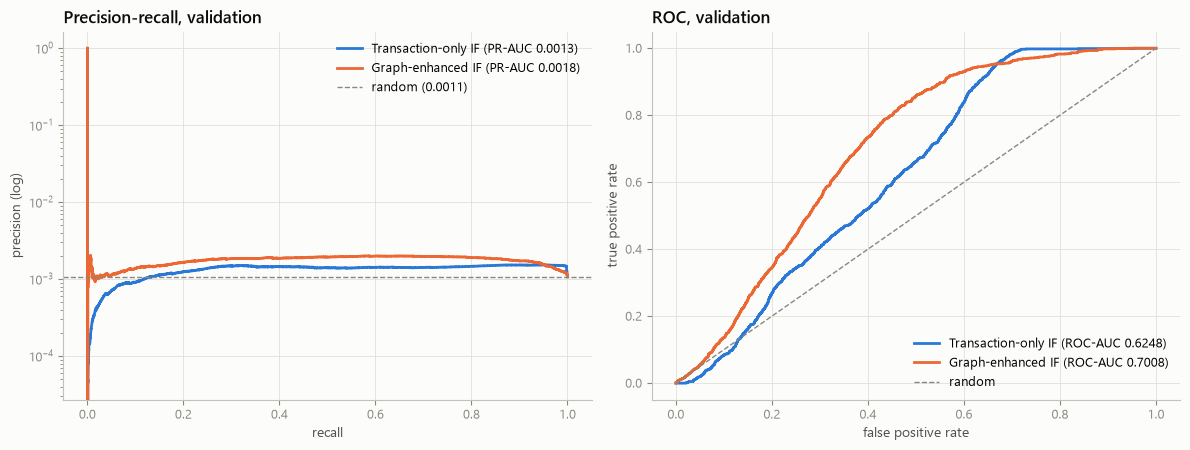

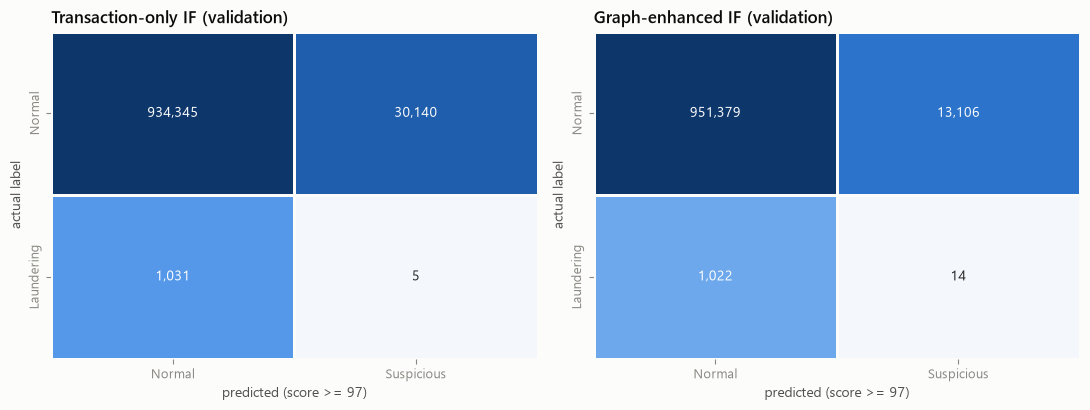

In [30]:
def curve_panels(y_true, raws, part, fname):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for m, raw in raws.items():
        p, r, _ = precision_recall_curve(y_true, raw)
        axes[0].plot(r, p, color=MODEL_COLORS[m], lw=2,
                     label=f"{md.MODEL_LABELS[m]} (PR-AUC {average_precision_score(y_true, raw):.4f})")
        fpr, tpr, _ = roc_curve(y_true, raw)
        axes[1].plot(fpr, tpr, color=MODEL_COLORS[m], lw=2,
                     label=f"{md.MODEL_LABELS[m]} (ROC-AUC {roc_auc_score(y_true, raw):.4f})")
    axes[0].axhline(y_true.mean(), color=PAL["muted"], ls="--", lw=1, label=f"random ({y_true.mean():.4f})")
    axes[0].set_yscale("log")
    axes[0].set(xlabel="recall", ylabel="precision (log)", title=f"Precision-recall, {part}")
    axes[1].plot([0, 1], [0, 1], color=PAL["muted"], ls="--", lw=1, label="random")
    axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title=f"ROC, {part}")
    for ax in axes:
        ax.legend(loc="best")
    fig.tight_layout()
    save(fig, fname)

def confusion_panels(y_true, scores, part, fname):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, (m, s) in zip(axes, scores.items()):
        cm = confusion_matrix(y_true, s >= HIGH_CUT, labels=[0, 1])
        sns.heatmap(cm, annot=[[f"{v:,}" for v in row] for row in cm], fmt="", cmap=SEQ, cbar=False,
                    linewidths=2, linecolor=PAL["surface"], ax=ax,
                    xticklabels=["Normal", "Suspicious"], yticklabels=["Normal", "Laundering"],
                    norm=matplotlib.colors.LogNorm(vmin=max(cm.min(), 1), vmax=cm.max()))
        ax.set_title(f"{md.MODEL_LABELS[m]} ({part})")
        ax.set_xlabel("predicted (score >= 97)")
        ax.set_ylabel("actual label")
    fig.tight_layout()
    save(fig, fname)

curve_panels(y_val, {m: t["val_raw"] for m, t in trained.items()}, "validation", "eval_curves_validation")
confusion_panels(y_val, {m: t["val_score"] for m, t in trained.items()}, "validation", "eval_confusion_validation")

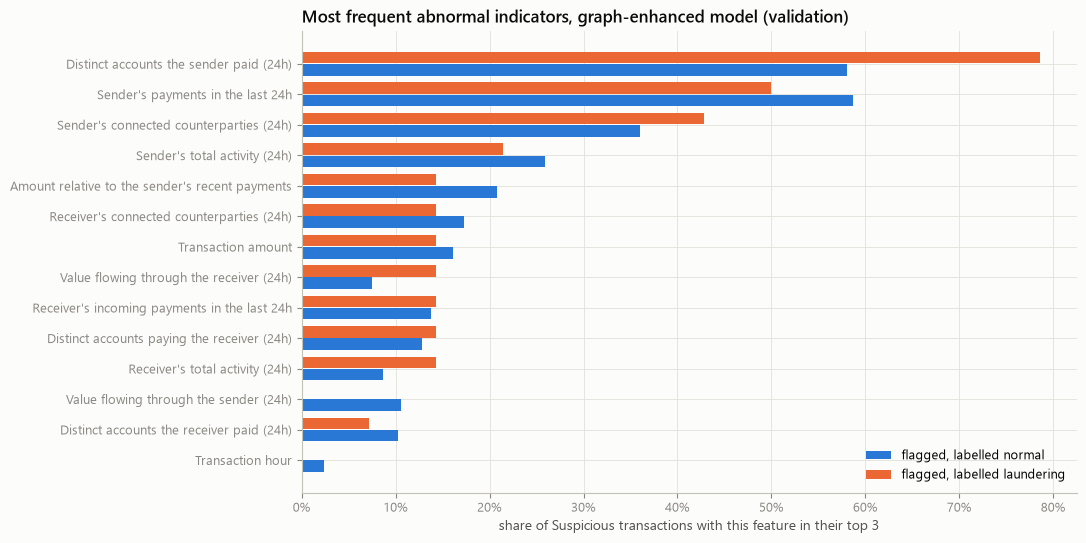

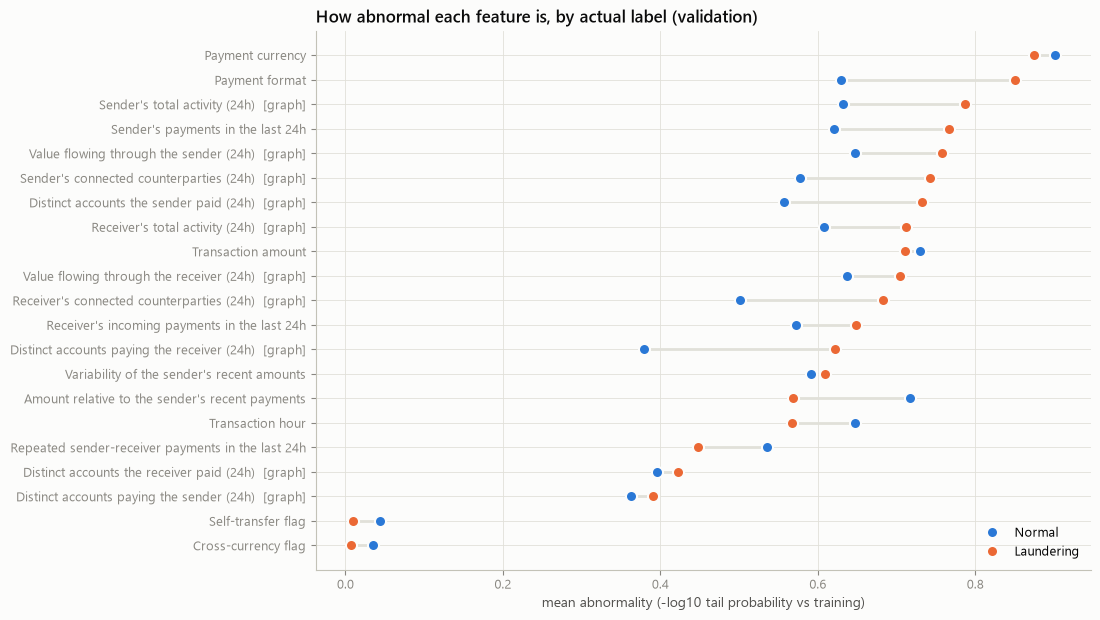

In [31]:
# Which features show up as top abnormal indicators? Explanations use only the inputs each model consumed.
def top_features_for(name, idx, scores):
    rows = idx[scores >= HIGH_CUT]
    tf = md.top_abnormal_features(F.iloc[rows], feature_reference, trained[name]["input_features"], k=3)
    tf["label"] = y[tf["row"].to_numpy()]
    return tf

val_top = {m: top_features_for(m, idx_val, t["val_score"]) for m, t in trained.items()}
tfg = val_top["graph_enhanced"]
share = (tfg.groupby(["feature_name", "label"])["row"].nunique()
            .unstack(fill_value=0)
            .div(tfg.groupby("label")["row"].nunique(), axis=1) * 100).rename(columns={0: "Normal", 1: "Laundering"})
share = share.reindex(share.max(axis=1).sort_values().index).tail(14)
fig, ax = plt.subplots(figsize=(10, 6))
yy = np.arange(len(share))
ax.barh(yy - 0.2, share.get("Normal", 0), height=0.38, color=LABEL_COLORS["Normal"], label="flagged, labelled normal")
ax.barh(yy + 0.2, share.get("Laundering", 0), height=0.38, color=LABEL_COLORS["Laundering"], label="flagged, labelled laundering")
ax.set_yticks(yy, [md.feature_label(f) for f in share.index])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlabel("share of Suspicious transactions with this feature in their top 3")
ax.set_title("Most frequent abnormal indicators, graph-enhanced model (validation)")
ax.legend(loc="lower right")
save(fig, "abnormal_features_frequency")

samp = np.concatenate([rng.choice(np.flatnonzero(y_val == 0), 100_000, replace=False), np.flatnonzero(y_val == 1)])
ab, _ = md.feature_abnormality(F.iloc[idx_val[samp]], feature_reference, fe.ALL_FEATURES)
med = ab.groupby(y_val[samp]).mean().T.rename(columns={0: "Normal", 1: "Laundering"}).sort_values("Laundering")
fig, ax = plt.subplots(figsize=(10, 7))
yy = np.arange(len(med))
ax.hlines(yy, med.min(axis=1), med.max(axis=1), color=PAL["grid"], lw=2)
for name in ("Normal", "Laundering"):
    ax.plot(med[name], yy, "o", ms=8, color=LABEL_COLORS[name], label=name, mec=PAL["surface"], mew=1.5)
ax.set_yticks(yy, [f"{md.feature_label(f)}{'  [graph]' if f in fe.GRAPH_FEATURES else ''}" for f in med.index])
ax.set_xlabel("mean abnormality (-log10 tail probability vs training)")
ax.set_title("How abnormal each feature is, by actual label (validation)")
ax.legend(loc="lower right")
save(fig, "abnormal_features_by_label")

## 15. Model comparison and selection (validation only)
The preferred approach is the model with the higher **validation PR-AUC**. A paired bootstrap of the validation
transactions gives a 95% interval for the difference.

Caveat: the bootstrap resamples individual transactions. Laundering transactions come in linked patterns, so this
interval is optimistic (too narrow).

In [32]:
cmp = val_metrics.set_index("model")
diff_val = paired_bootstrap(y_val, trained["transaction_only"]["val_raw"], trained["graph_enhanced"]["val_raw"])
SELECTED = max(trained, key=lambda m: average_precision_score(y_val, trained[m]["val_raw"]))
other = "transaction_only" if SELECTED == "graph_enhanced" else "graph_enhanced"
selection = {
    "selected_model": SELECTED,
    "criterion": "highest validation PR-AUC",
    "validation_pr_auc": {m: float(average_precision_score(y_val, t["val_raw"])) for m, t in trained.items()},
    "pr_auc_difference_graph_minus_transaction_95ci": [float(v) for v in diff_val[[0, 2]]],
    "pr_auc_difference_graph_minus_transaction_median": float(diff_val[1]),
}
display(Markdown(
    f"**Selected: {md.MODEL_LABELS[SELECTED]}.** Validation PR-AUC "
    f"{selection['validation_pr_auc'][SELECTED]:.4f} vs {selection['validation_pr_auc'][other]:.4f} "
    f"({md.MODEL_LABELS[other]}). Graph-enhanced minus transaction-only: median {diff_val[1]:+.4f}, "
    f"95% bootstrap interval [{diff_val[0]:+.4f}, {diff_val[2]:+.4f}]. "
    + ("The interval excludes zero." if diff_val[0] > 0 or diff_val[2] < 0 else
       "The interval includes zero, so the two models are **not** clearly different on validation.")))

**Selected: Graph-enhanced IF.** Validation PR-AUC 0.0018 vs 0.0013 (Transaction-only IF). Graph-enhanced minus transaction-only: median +0.0004, 95% bootstrap interval [+0.0003, +0.0005]. The interval excludes zero.

## 16. Final evaluation on the test period (Sep 9–10)
The selection above is fixed. The test transactions are scored by both final model configurations, using the same transactions for each.

**Disclosure.** This is the **second** time the test days have been scored. The first, one-hot-only version (see the
revision note in Section 9) scored them once before it was revised. The revision was decided from validation results only,
and the first version's test numbers were archived without being viewed. Both are shown below. The first version's
test results are therefore not a selection target, and the second version's are not a fully untouched estimate.

In [33]:
for m, t in trained.items():
    X_test = t["pre"].transform(F.iloc[idx_test][md.MODEL_FEATURES[m]])   # preprocessor drops unused columns
    t["test_raw"] = md.raw_anomaly_score(t["model"], X_test)
    t["test_score"] = md.normalize_scores(t["test_raw"], normalizers[m])
    del X_test
test_metrics = pd.DataFrame([evaluate(m, y_test, t["test_raw"], t["test_score"], "test") for m, t in trained.items()])
diff_test = paired_bootstrap(y_test, trained["transaction_only"]["test_raw"], trained["graph_enhanced"]["test_raw"])
comparison = pd.concat([val_metrics, test_metrics], ignore_index=True)
display(comparison.set_index(["data", "model"]).T)
display(Markdown(
    f"**Test (selected model, {md.MODEL_LABELS[SELECTED]}):** PR-AUC "
    f"{test_metrics.set_index('model').loc[md.MODEL_LABELS[SELECTED], 'pr_auc']:.4f} "
    f"(random = {y_test.mean():.5f}). Graph-enhanced minus transaction-only on test: median {diff_test[1]:+.4f}, "
    f"95% bootstrap interval [{diff_test[0]:+.4f}, {diff_test[2]:+.4f}]."))

data                          validation                                  test                  
model                Transaction-only IF Graph-enhanced IF Transaction-only IF Graph-enhanced IF
transactions               965521.000000     965521.000000       862788.000000     862788.000000
laundering                   1036.000000       1036.000000          956.000000        956.000000
prevalence                      0.001073          0.001073            0.001108          0.001108
pr_auc                          0.001335          0.001760            0.001388          0.001703
roc_auc                         0.624811          0.700767            0.624567          0.668539
suspicious_precision            0.000166          0.001067            0.000120          0.001291
suspicious_recall               0.004826          0.013514            0.003138          0.050209
suspicious_f1                   0.000321          0.001978            0.000232          0.002517
suspicious_flagged          30145.000000      13120.000000        24957.000000      37184.000000
suspicious_tp                   5.000000         14.000000            3.000000         48.000000
suspicious_fp               30140.000000      13106.000000        24954.000000      37136.000000
suspicious_fn                1031.000000       1022.000000          953.000000        908.000000
suspicious_tn              934345.000000     951379.000000       836878.000000     824696.000000
critical_precision              0.000000          0.000000            0.000000          0.000575
critical_recall                 0.000000          0.000000            0.000000          0.004184
critical_f1                     0.000000          0.000000            0.000000          0.001011
critical_flagged             4442.000000        294.000000         4129.000000       6957.000000
critical_tp                     0.000000          0.000000            0.000000          4.000000
critical_fp                  4442.000000        294.000000         4129.000000       6953.000000
critical_fn                  1036.000000       1036.000000          956.000000        952.000000
critical_tn                960043.000000     964191.000000       857703.000000     854879.000000

**Test (selected model, Graph-enhanced IF):** PR-AUC 0.0017 (random = 0.00111). Graph-enhanced minus transaction-only on test: median +0.0003, 95% bootstrap interval [+0.0002, +0.0005].

In [34]:
# Version history: first (one-hot only) vs current version, from the archived run.
V1_DIR = C.OUTPUTS_DIR / "archive" / "v1_onehot" / "metrics"
version_cmp = None
if (V1_DIR / "model_comparison.csv").exists():
    v1 = pd.read_csv(V1_DIR / "model_comparison.csv").assign(version="v1: one-hot only")
    v2 = comparison.assign(version="v2: encoding chosen on validation")
    keep = ["version", "data", "model", "pr_auc", "roc_auc", "suspicious_precision", "suspicious_recall",
            "critical_recall"]
    version_cmp = pd.concat([v1[keep], v2[keep]], ignore_index=True)
    display(version_cmp.style.format({c: "{:.4f}" for c in keep[3:]}).hide(axis="index"))
    version_cmp.to_csv(C.METRICS_DIR / "version_comparison.csv", index=False)
else:
    print("archived first-version results not found - version comparison skipped")

version,data,model,pr_auc,roc_auc,suspicious_precision,suspicious_recall,critical_recall
v1: one-hot only,validation,Transaction-only IF,0.0013,0.6248,0.0002,0.0048,0.0000
v1: one-hot only,validation,Graph-enhanced IF,0.0017,0.7017,0.0010,0.0183,0.0000
v1: one-hot only,test,Transaction-only IF,0.0014,0.6246,0.0001,0.0031,0.0000
v1: one-hot only,test,Graph-enhanced IF,0.0017,0.6805,0.0009,0.0324,0.0031
v2: encoding chosen on validation,validation,Transaction-only IF,0.0013,0.6248,0.0002,0.0048,0.0000
v2: encoding chosen on validation,validation,Graph-enhanced IF,0.0018,0.7008,0.0011,0.0135,0.0000
v2: encoding chosen on validation,test,Transaction-only IF,0.0014,0.6246,0.0001,0.0031,0.0000
v2: encoding chosen on validation,test,Graph-enhanced IF,0.0017,0.6685,0.0013,0.0502,0.0042


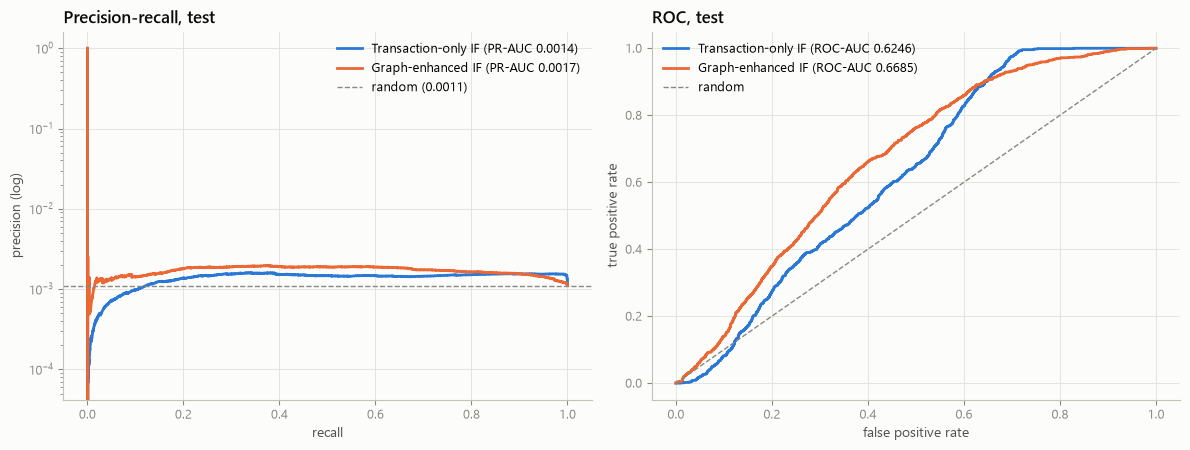

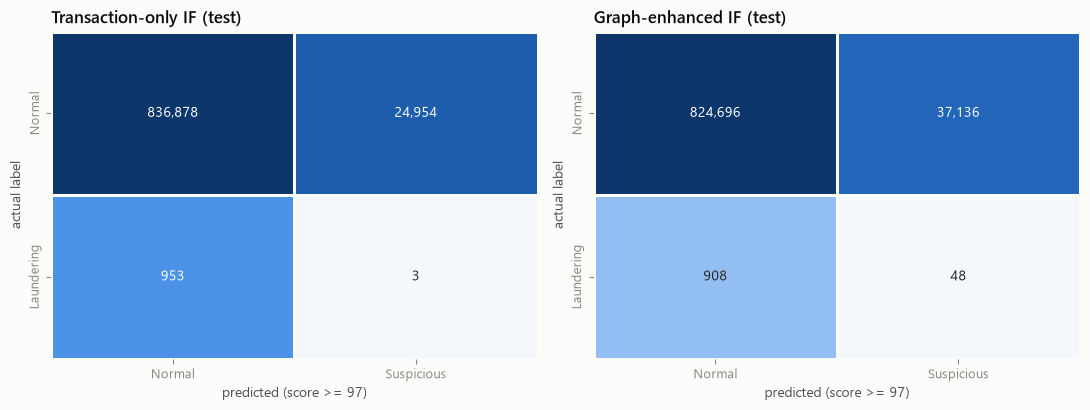

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


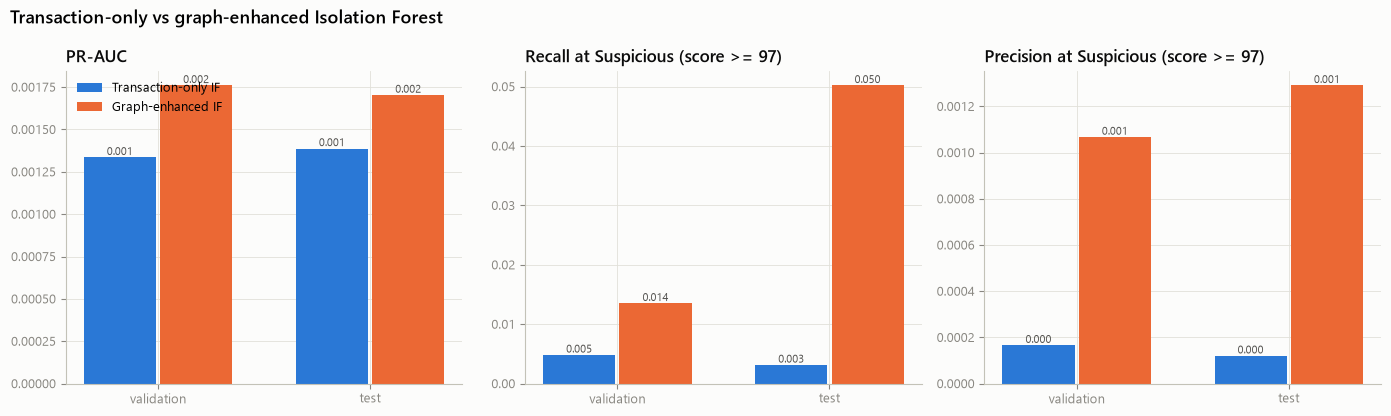

In [35]:
curve_panels(y_test, {m: t["test_raw"] for m, t in trained.items()}, "test", "eval_curves_test")
confusion_panels(y_test, {m: t["test_score"] for m, t in trained.items()}, "test", "eval_confusion_test")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, metric, title in zip(axes, ["pr_auc", "suspicious_recall", "suspicious_precision"],
                             ["PR-AUC", "Recall at Suspicious (score >= 97)", "Precision at Suspicious (score >= 97)"]):
    xs = np.arange(2)
    for j, m in enumerate(trained):
        vals = comparison[comparison["model"] == md.MODEL_LABELS[m]].set_index("data").loc[["validation", "test"], metric]
        bars = ax.bar(xs + (j - 0.5) * 0.36, vals.values, width=0.34, color=MODEL_COLORS[m], label=md.MODEL_LABELS[m])
        for b, v in zip(bars, vals.values):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8, color=PAL["ink2"])
    ax.set_xticks(xs, ["validation", "test"])
    ax.set_title(title)
axes[0].legend(loc="upper left")
fig.suptitle("Transaction-only vs graph-enhanced Isolation Forest", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout()
save(fig, "model_comparison")

In [36]:
test_top = top_features_for(SELECTED, idx_test, trained[SELECTED]["test_score"])
test_top.insert(0, "transaction_reference", modelled.loc[test_top["row"], "transaction_reference"].to_numpy())
print(f"Suspicious test transactions ({md.MODEL_LABELS[SELECTED]}): {test_top['row'].nunique():,}")
crit_rows = idx_test[trained[SELECTED]["test_score"] >= CRIT_CUT]
example_rows = list(crit_rows[y[crit_rows] == 1][:3]) + list(crit_rows[y[crit_rows] == 0][:2])
for r in example_rows:
    t = test_top[test_top["row"] == r]
    head = modelled.loc[r]
    display(Markdown(
        f"**{head['transaction_reference']}** · {head['timestamp']} · {head['sender_id']} → {head['receiver_id']} · "
        f"USD {F.at[r, 'amount_usd']:,.2f} · {head['payment_format']} · anomaly score "
        f"{trained[SELECTED]['test_score'][np.searchsorted(idx_test, r)]:.2f} · actual label: "
        f"{'laundering' if y[r] else 'normal'}"))
    display(t[["rank", "feature_name", "feature_value", "contribution_score", "description"]]
              .style.format({"contribution_score": "{:.2f}"}).hide(axis="index"))

Suspicious test transactions (Graph-enhanced IF): 37,184


**HI-Small-04300704** · 2022-09-09 02:49:00 · 070|100428660 → 0030775|80F2F7770 · USD 1,790,434.47 · Cash · anomaly score 99.95 · actual label: laundering

rank,feature_name,feature_value,contribution_score,description
1,sender_amount_deviation_24h,7.304326,2.09,Amount relative to the sender's recent payments is unusually high (+7.30 (log scale)); only 0.81% of training transactions are this high or higher.
2,amount_usd,1790434.470000,1.90,"Transaction amount is unusually high (USD 1,790,434.47); only 1.3% of training transactions are this high or higher."
3,sender_out_count_24h,19094.000000,1.84,"Sender's payments in the last 24h is unusually high (19,094); only 1.4% of training transactions are this high or higher."


**HI-Small-04604534** · 2022-09-09 14:02:00 · 070|100428660 → 012|8032F7300 · USD 19.64 · Cash · anomaly score 99.80 · actual label: laundering

rank,feature_name,feature_value,contribution_score,description
1,sender_in_degree_24h,326.000000,2.19,Distinct accounts paying the sender (24h) is unusually high (326); only 0.65% of training transactions are this high or higher.
2,sender_txn_count_24h,21181.000000,1.87,"Sender's total activity (24h) is unusually high (21,181); only 1.4% of training transactions are this high or higher."
3,sender_out_count_24h,20855.000000,1.85,"Sender's payments in the last 24h is unusually high (20,855); only 1.4% of training transactions are this high or higher."


**HI-Small-04645617** · 2022-09-09 15:32:00 · 070|100428660 → 0012979|807CEBAF0 · USD 58.26 · Credit Card · anomaly score 99.75 · actual label: laundering

rank,feature_name,feature_value,contribution_score,description
1,sender_in_degree_24h,362.000000,2.27,Distinct accounts paying the sender (24h) is unusually high (362); only 0.54% of training transactions are this high or higher.
2,sender_txn_count_24h,21531.000000,1.90,"Sender's total activity (24h) is unusually high (21,531); only 1.3% of training transactions are this high or higher."
3,sender_out_count_24h,21169.000000,1.88,"Sender's payments in the last 24h is unusually high (21,169); only 1.3% of training transactions are this high or higher."


**HI-Small-04215395** · 2022-09-09 00:09:00 · 070|100428660 → 001|8000EEE80 · USD 3,943.60 · Cheque · anomaly score 99.53 · actual label: normal

rank,feature_name,feature_value,contribution_score,description
1,receiver_out_degree_24h,7.000000,2.35,Distinct accounts the receiver paid (24h) is unusually high (7); only 0.44% of training transactions are this high or higher.
2,sender_out_degree_24h,9215.000000,2.00,"Distinct accounts the sender paid (24h) is unusually high (9,215); only 0.99% of training transactions are this high or higher."
3,sender_counterparties_24h,9219.000000,1.89,"Sender's connected counterparties (24h) is unusually high (9,219); only 1.3% of training transactions are this high or higher."


**HI-Small-04215474** · 2022-09-09 00:12:00 · 070|100428660 → 01420|8002B9BF0 · USD 166.45 · Credit Card · anomaly score 99.57 · actual label: normal

rank,feature_name,feature_value,contribution_score,description
1,receiver_volume_24h,26115778.280000,2.01,"Value flowing through the receiver (24h) is unusually high (USD 26,115,778.28); only 0.98% of training transactions are this high or higher."
2,sender_out_degree_24h,9212.000000,2.00,"Distinct accounts the sender paid (24h) is unusually high (9,212); only 1% of training transactions are this high or higher."
3,sender_counterparties_24h,9216.000000,1.89,"Sender's connected counterparties (24h) is unusually high (9,216); only 1.3% of training transactions are this high or higher."


## 17. Model persistence
Saved to `models/`:
| File | Contents |
|---|---|
| `transaction_model.joblib` | Model 1 IsolationForest |
| `graph_model.joblib` | Model 2 IsolationForest |
| `preprocessing.joblib` | `{"transaction_only": ColumnTransformer, "graph_enhanced": ColumnTransformer}` |
| `scoring_reference.joblib` | FX rates, score-normalisation quantiles, training reference distributions for explanations |
| `history_tail.joblib` | Last 24h of transactions (no labels), the history context for batches that start after the data ends |
| `model_metadata.json` | Schema, feature lists, thresholds, settings, metrics, versions, dataset info and artifact checksums |

Results go to `outputs/metrics/` and `outputs/reports/`.

In [37]:
joblib.dump(trained["transaction_only"]["model"], C.MODELS_DIR / ARTIFACT_FILES["transaction_model"])
joblib.dump(trained["graph_enhanced"]["model"], C.MODELS_DIR / ARTIFACT_FILES["graph_model"])
joblib.dump({m: t["pre"] for m, t in trained.items()}, C.MODELS_DIR / ARTIFACT_FILES["preprocessing"])
joblib.dump({"fx": fx, "normalizers": normalizers, "feature_reference": feature_reference},
            C.MODELS_DIR / ARTIFACT_FILES["scoring_reference"])
history_tail = fe.history_tail(modelled)
joblib.dump(history_tail, C.MODELS_DIR / ARTIFACT_FILES["history_tail"])

def to_py(x):
    if isinstance(x, dict):
        return {str(k): to_py(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [to_py(v) for v in x]
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        return float(x)
    if isinstance(x, (pd.Timestamp,)):
        return str(x)
    return x

metadata = {
    "project": "CoDetect - Financial Fraud Detection With Anomaly Feature Detection",
    "created": pd.Timestamp.now().isoformat(timespec="seconds"),
    "run_mode": RUN_MODE, "random_seed": SEED, "library_versions": versions,
    "dataset": {"name": C.DATASET_NAME, "file": C.TRANSACTIONS_FILE.name,
                "sha256": sha256(C.TRANSACTIONS_FILE),
                "source": "https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml",
                "official_project": "https://github.com/IBM/AML-Data", "licence": "CDLA-Sharing-1.0",
                "column_map": C.COLUMN_MAP, "cleaning_report": clean_report,
                "split_windows": C.SPLIT_WINDOWS,
                "split_counts": split_tbl[["rows", "laundering"]].to_dict(orient="index")},
    "feature_version": fe.FEATURE_VERSION,
    "history_window_minutes": fe.HISTORY_WINDOW_MINUTES,
    "history_rule": "features of a transaction at minute m use only transactions in [m-1440, m-1]",
    "feature_schema": fe.FEATURE_SCHEMA,
    "model_features": md.MODEL_FEATURES,
    "encoding": {m: t["encoding"] for m, t in trained.items()},
    "input_features": {m: t["input_features"] for m, t in trained.items()},
    "encoded_features": {m: t["encoded_features"] for m, t in trained.items()},
    "required_input_columns": fe.REQUIRED_COLUMNS,
    "hyperparameters": {m: {"n_estimators": N_ESTIMATORS, **t["config"], "contamination": "auto",
                            "fit_rows": int(len(idx_fit))} for m, t in trained.items()},
    "hyperparameter_grid": {"encodings": list(md.ENCODINGS), "settings": GRID},
    "revision_history": [
        {"version": "v1", "change": "one-hot encoding only",
         "note": "test days scored once; results archived unopened in outputs/archive/v1_onehot before revision"},
        {"version": "v2", "change": "encoding (onehot / frequency / numeric_only) added to the validation search",
         "reason": "v1 validation: Isolation Forest isolated rare currencies, cross-currency and self-transfer "
                   "values first; labelled laundering is common-looking on those columns"}],
    "score_convention": {"raw": "-IsolationForest.score_samples (higher = more abnormal)",
                         "anomaly_score": "percentile (0-100) of raw score among training-period raw scores",
                         "note": "an anomaly score is a rarity rank, not a fraud probability"},
    "risk_levels": [{"level": n, "min_score": c} for n, c in md.RISK_LEVELS],
    "suspicious_levels": list(md.SUSPICIOUS_LEVELS),
    "abnormal_feature_method": "-log10 tail probability vs training reference sample; top 3 per suspicious transaction",
    "selected_model": SELECTED, "selection": selection,
    "combined_anomaly_score": "anomaly score of the selected model",
    "metrics": {"validation": val_metrics.to_dict(orient="records"),
                "test": test_metrics.to_dict(orient="records"),
                "test_pr_auc_difference_graph_minus_transaction_95ci": [float(diff_test[0]), float(diff_test[2])]},
    "history_tail": {"rows": int(len(history_tail)),
                     "from": str(pd.Timestamp(int(history_tail["minute"].min()) * 60, unit="s")),
                     "to": str(pd.Timestamp(int(history_tail["minute"].max()) * 60, unit="s"))},
}
metadata["artifact_sha256"] = {f: sha256(C.MODELS_DIR / f) for k, f in ARTIFACT_FILES.items() if k != "metadata"}
(C.MODELS_DIR / ARTIFACT_FILES["metadata"]).write_text(json.dumps(to_py(metadata), indent=2, default=str))

# results
pd.concat([trained[m]["grid"] for m in trained]).to_csv(C.METRICS_DIR / "hyperparameter_search.csv", index=False)
comparison.to_csv(C.METRICS_DIR / "model_comparison.csv", index=False)
risk_tbl.to_csv(C.METRICS_DIR / "risk_distribution.csv", index=False)
(C.METRICS_DIR / "metrics.json").write_text(json.dumps(to_py(metadata["metrics"] | {"selection": selection}), indent=2))
scored = []
for part, idx in (("validation", idx_val), ("test", idx_test)):
    key = "val" if part == "validation" else "test"
    scored.append(pd.DataFrame({
        "transaction_reference": modelled.loc[idx, "transaction_reference"].to_numpy(), "split": part,
        "actual_label": y[idx],
        **{f"{'transaction' if m == 'transaction_only' else 'graph'}_{kind}": trained[m][f"{key}_{kind2}"]
           for m in trained for kind, kind2 in (("raw_score", "raw"), ("anomaly_score", "score"))}}))
scored = pd.concat(scored, ignore_index=True)
for short in ("transaction", "graph"):
    scored[f"{short}_risk_level"] = md.risk_level(scored[f"{short}_anomaly_score"])
sel_short = "transaction" if SELECTED == "transaction_only" else "graph"
scored["risk_level"] = scored[f"{sel_short}_risk_level"]
scored["anomaly_status"] = md.anomaly_status(scored["risk_level"])
scored.to_csv(C.REPORTS_DIR / "scored_validation_test.csv.gz", index=False,
              compression={"method": "gzip", "compresslevel": 1})
test_top.drop(columns="row").to_csv(C.REPORTS_DIR / "test_suspicious_top_features.csv", index=False)
for f in sorted(C.MODELS_DIR.iterdir()):
    print(f"{f.relative_to(ROOT)}  {f.stat().st_size / 1e6:8.2f} MB")

models\graph_model.joblib      2.54 MB
models\history_tail.joblib     15.72 MB
models\model_metadata.json      0.02 MB
models\preprocessing.joblib      0.01 MB
models\scoring_reference.joblib     15.28 MB
models\transaction_model.joblib      2.01 MB


## 18. Inference module and prediction-consistency check
`services/fraud_inference.FraudInference` reloads every artifact from disk, checks the checksums and feature version,
and scores **raw, CSV-shaped records** through the full path:
column mapping → cleaning → 24h-window features → both models → normalisation → risk level → explanations.

Here it scores one real hour from the test period (Sep 10, 12:00–13:00). The records are rebuilt in the raw CSV
format, and the 24 hours before them are passed as history. The results must match the notebook's in-memory
scores exactly.

In [38]:
engine = FraudInference(C.MODELS_DIR)
b_mask = ((modelled["timestamp"] >= "2022-09-10 12:00") & (modelled["timestamp"] < "2022-09-10 13:00")).to_numpy()
batch_clean = modelled[b_mask]
raw_batch = batch_clean[list(C.COLUMN_MAP)].rename(columns=C.COLUMN_MAP)
raw_batch[C.COLUMN_MAP["timestamp"]] = batch_clean["timestamp"].dt.strftime(fe.TIMESTAMP_FORMAT)
raw_batch["transaction_reference"] = batch_clean["transaction_reference"].to_numpy()
history_ctx = modelled.loc[modelled["minute"] < int(batch_clean["minute"].min()), fe.HISTORY_COLUMNS]

t0 = time.perf_counter()
res = engine.score(raw_batch.reset_index(drop=True), history=history_ctx)
print(f"scored {len(res.results):,} raw records in {time.perf_counter() - t0:.1f}s; "
      f"history rows used: {res.history_info['history_rows_used']:,}")

nb = scored[scored["split"] == "test"].set_index("transaction_reference")
got = res.results.set_index("transaction_reference")
nb = nb.loc[got.index]
consistency = pd.Series({
    "transactions compared": len(got),
    "max |transaction raw score diff|": float(np.abs(got["transaction_raw_score"] - nb["transaction_raw_score"]).max()),
    "max |graph raw score diff|": float(np.abs(got["graph_raw_score"] - nb["graph_raw_score"]).max()),
    "max |anomaly score diff|": float(np.abs(got["combined_anomaly_score"] - nb[f"{sel_short}_anomaly_score"]).max()),
    "risk levels identical": bool((got["risk_level"].to_numpy() == nb["risk_level"].to_numpy()).all()),
    "labels passed through, not used": bool((got["actual_label"].to_numpy() == nb["actual_label"].to_numpy()).all()),
}, name="value").to_frame()
display(consistency)
assert consistency.loc["max |transaction raw score diff|", "value"] < 1e-9
assert consistency.loc["max |graph raw score diff|", "value"] < 1e-9
assert consistency.loc["risk levels identical", "value"]
display(res.results[res.results["anomaly_status"] == "Suspicious"].head(5))
display(res.explanations.head(6))

# A batch that does not start after the saved history must be given explicit history:
try:
    engine.score(raw_batch.head(20))
except fe.HistoryOverlapError as exc:
    print("expected validation message:", exc)

scored 8,027 raw records in 1.3s; history rows used: 431,969


,value
transactions compared,8027
max |transaction raw score diff|,0.0
max |graph raw score diff|,0.0
max |anomaly score diff|,0.0
risk levels identical,True
"labels passed through, not used",True


,transaction_reference,timestamp,sender_id,receiver_id,amount_usd,payment_format,transaction_raw_score,transaction_anomaly_score,transaction_risk_level,graph_raw_score,graph_anomaly_score,graph_risk_level,model_name,combined_anomaly_score,risk_level,anomaly_status,actual_label
36,HI-Small-04983315,2022-09-10 12:00:00,070|100428660,002845|80A020320,26.300000,Credit Card,0.415099,48.112274,Low,0.604868,97.122790,High,Graph-enhanced IF,97.122790,High,Suspicious,0
42,HI-Small-04983415,2022-09-10 12:00:00,070|100428660,0019601|80C26C8B0,15871.940000,Cheque,0.403361,35.259949,Low,0.614392,97.978890,High,Graph-enhanced IF,97.978890,High,Suspicious,0
60,HI-Small-04983778,2022-09-10 12:00:00,070|100428660,028255|81172DA80,20410.640000,Credit Card,0.417974,51.816038,Low,0.614029,97.950977,High,Graph-enhanced IF,97.950977,High,Suspicious,0
67,HI-Small-04983971,2022-09-10 12:00:00,070|100428660,0239330|814367960,7821.620000,Credit Card,0.427993,64.161112,Low,0.652875,99.642867,Critical,Graph-enhanced IF,99.642867,Critical,Suspicious,0
73,HI-Small-04984071,2022-09-10 12:00:00,070|1004286A8,022758|80149C170,44.070776,Credit Card,0.427811,63.950237,Low,0.623206,98.579351,High,Graph-enhanced IF,98.579351,High,Suspicious,0


,transaction_reference,row,rank,feature_name,feature_group,feature_value,contribution_score,direction,description
0,HI-Small-04983315,36,1,sender_in_degree_24h,graph,2.620000e+02,1.968188,high,Distinct accounts paying the sender (24h) is u...
1,HI-Small-04983315,36,2,sender_volume_24h,graph,4.451836e+09,1.609949,high,Value flowing through the sender (24h) is unus...
2,HI-Small-04983315,36,3,sender_counterparties_24h,graph,6.767000e+03,1.544850,high,Sender's connected counterparties (24h) is unu...
3,HI-Small-04983415,42,1,sender_in_degree_24h,graph,2.620000e+02,1.968188,high,Distinct accounts paying the sender (24h) is u...
4,HI-Small-04983415,42,2,sender_volume_24h,graph,4.451836e+09,1.609949,high,Value flowing through the sender (24h) is unus...
5,HI-Small-04983415,42,3,sender_counterparties_24h,graph,6.767000e+03,1.544850,high,Sender's connected counterparties (24h) is unu...


expected validation message: This batch starts before the end of the saved training history (2022-09-10 23:59:00). Pass the transactions from the 24 hours before the batch as history.


### How Flask will call this module (Stage 2 contract)
```python
from services.fraud_inference import FraudInference, ArtifactError
engine = FraudInference("ml_artifacts")          # raises ArtifactError if anything is missing or incompatible
clean, report = engine.prepare(uploaded_df)      # SchemaError -> show "missing columns" message
problems = engine.validate(clean)                # e.g. unknown currency -> show message, do not score
result = engine.score(clean, already_clean=True, history=earlier_24h_from_db)
# result.results      -> Fraud_Analysis rows (transaction/graph/combined scores, risk_level, anomaly_status)
# result.explanations -> Anomaly_Features rows (feature_name, feature_value, contribution_score, description)
# High / Critical     -> Fraud_Alerts
```

## 19. Summary
Everything below is printed from the computed results above.

In [39]:
v = val_metrics.set_index("model"); t_ = test_metrics.set_index("model")
lines = [f"- Data: {len(modelled):,} modelled transactions (IBM AML HI-Small); train {len(idx_train):,}, "
         f"validation {len(idx_val):,}, test {len(idx_test):,}; laundering prevalence in test {y_test.mean():.4%}."]
for m in trained:
    L = md.MODEL_LABELS[m]
    lines.append(f"- {L}: validation PR-AUC {v.loc[L, 'pr_auc']:.4f} / ROC-AUC {v.loc[L, 'roc_auc']:.4f}; "
                 f"test PR-AUC {t_.loc[L, 'pr_auc']:.4f} / ROC-AUC {t_.loc[L, 'roc_auc']:.4f}; "
                 f"test recall at Suspicious {t_.loc[L, 'suspicious_recall']:.3f} with precision "
                 f"{t_.loc[L, 'suspicious_precision']:.4f} ({t_.loc[L, 'suspicious_flagged']:,} flagged).")
lines.append("- Encodings selected on validation: " + ", ".join(
    f"{md.MODEL_LABELS[m]} = `{t['encoding']}`" for m, t in trained.items())
    + ". The test days were scored once earlier by the one-hot-only first version (see Sections 9 and 16).")
lines.append(f"- Selected on validation: {md.MODEL_LABELS[SELECTED]}. Graph minus transaction PR-AUC, 95% bootstrap "
             f"interval: validation [{diff_val[0]:+.4f}, {diff_val[2]:+.4f}], test [{diff_test[0]:+.4f}, {diff_test[2]:+.4f}].")
lines.append(f"- Reloaded inference module reproduced the notebook scores on {len(got):,} raw records "
             f"(max raw-score difference {max(consistency.loc['max |transaction raw score diff|', 'value'], consistency.loc['max |graph raw score diff|', 'value']):.1e}).")
lines.append(f"- Figures saved: {len(FIGS)} in outputs/figures; total notebook runtime "
             f"{(time.perf_counter() - NOTEBOOK_START) / 60:.1f} min ({RUN_MODE} mode).")
display(Markdown("\n".join(lines)))

- Data: 5,077,228 modelled transactions (IBM AML HI-Small); train 2,134,000, validation 965,521, test 862,788; laundering prevalence in test 0.1108%.
- Transaction-only IF: validation PR-AUC 0.0013 / ROC-AUC 0.6248; test PR-AUC 0.0014 / ROC-AUC 0.6246; test recall at Suspicious 0.003 with precision 0.0001 (24,957 flagged).
- Graph-enhanced IF: validation PR-AUC 0.0018 / ROC-AUC 0.7008; test PR-AUC 0.0017 / ROC-AUC 0.6685; test recall at Suspicious 0.050 with precision 0.0013 (37,184 flagged).
- Encodings selected on validation: Transaction-only IF = `onehot`, Graph-enhanced IF = `numeric_only`. The test days were scored once earlier by the one-hot-only first version (see Sections 9 and 16).
- Selected on validation: Graph-enhanced IF. Graph minus transaction PR-AUC, 95% bootstrap interval: validation [+0.0003, +0.0005], test [+0.0002, +0.0005].
- Reloaded inference module reproduced the notebook scores on 8,027 raw records (max raw-score difference 0.0e+00).
- Figures saved: 18 in outputs/figures; total notebook runtime 10.0 min (quick mode).

**Reading the results responsibly**
* Isolation Forest is unsupervised. It finds *unusual* transactions, and most unusual transactions are not laundering,
  so precision at any practical alert volume is low. Low precision is the expected outcome for this method on 0.1% prevalence.
* Whether graph features help is the measured difference above, with its uncertainty. It is not an assumption.
* The bootstrap intervals resample individual transactions and ignore the linked structure of laundering patterns, so they are optimistic.
* The data is synthetic. Patterns such as "81% of laundering is ACH" come from the simulator and may not hold in real banking data.